# SSP-SIR time range: 30 vs 40 vs 50 ms

Re-runs the PRIME calibration **offline, exactly as it ran online**, at three SSP-SIR
`timerange` widths, then replays every single pulse of the intervention and evaluation
blocks through each resulting calibration. Nothing in `prime/` is modified or written to:
the decider package is only put on `sys.path` with `sys.dont_write_bytecode = True`, and a
SHA-256 manifest of every `prime/**/*.py` is checked at the start and again at the end.

## What the parameter actually is

`ssp_sir_opts.timerange = ['automatic', T]`, read by `ssp_sir_to_average`
(`utils/ssp_sir_python.py`). `T` is the **width in ms of a boxcar moving average** over the
squared >100 Hz evoked power, averaged across channels, normalised to max 1 and
square-rooted. The result is a per-sample blend weight `k(t)`:

    out(t) = k(t) * suppressed(t) + (1 - k(t)) * original(t)

so **lower `k` means less suppression**.

**It is not a purely temporal change.** The kernel multiplies the high-passed data
*before* the SVD (`ssp_sir_python.py:36`), so it also determines the artifact topographies
`U` → the suppression matrix `P`, the number of components removed, and `M` → both SIR
projection matrices. Section 1 quantifies all of it.

## Why these three values

Because the envelope is a boxcar of width `T` over a signal whose >100 Hz power is
concentrated before ~15 ms, the kernel steps down at **≈ 13 + T/2 ms**. On pilot003 that
puts the step at 38→39 ms for `T = 50` — **inside the dipole window [38, 50]** — and at
33→34 and 28→29 ms for `T = 40` and `T = 30`, outside it. That 38→39 ms step is the
artifact documented in `claude/TEP_diagnostics_notes.md` Part C. Section 1 reproduces it
and measures whether 40 and 30 remove it from the measurement window.

## Reading the results

Shorter `T` lowers the kernel **and** removes a principal component, so amplitudes are
expected to rise for two reasons that both mean *less suppression*. Amplitude alone
therefore cannot rank the settings; sections 9 and 10 carry the companion diagnostics
(evoked R², single-trial R², >100 Hz muscle residual, and the amplitude/out-of-window-norm
correlation) that say whether a rise is signal or noise floor.

## Scope

Post-stimulus chain and TEP amplitude only. The PRIME model, its predictions and its
finetuning are deliberately **not** replayed — no `OnlinePredictor`, no torch, no GPU.
Pulses stay where they were online.

In [49]:
# ============================== PARAMETERS ==============================
SUBJECTS        = ["pilot005"]      # add "pilot004", "pilot005" to run more sessions
SESSION_ID      = "ses-prime"
RUN_ID          = None              # None -> the one run folder with prime/trials_intervention.csv

SETTINGS        = [50, 40, 30]      # SSP-SIR timerange widths in ms; SETTINGS[0] is the control
REFERENCE_T     = 50                # must reproduce the shipped calibration bundle exactly
QUARTILE_REF_T  = 50                # the setting whose TEP amplitudes freeze the quartile split

LIMIT_PER_ARM   = None              # None = all trials; e.g. 20 for a smoke test
N_VALIDATE      = 25                # trials per setting for the split-path equality check
BOOTSTRAP_N     = 500               # resamples for the dipole-stability yardstick
BOOTSTRAP_SEED  = 201

SAVE_OUTPUTS    = True
OUT_NAME        = "offline_sspsir"  # <LOOP_ROOT>/<OUT_NAME>/sub-<ID>/sspsir_<T>ms/

In [50]:
# ============================== SETUP ==============================
import contextlib, hashlib, io, json, os, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.signal import butter, filtfilt
from scipy.stats import median_abs_deviation, zscore

warnings.filterwarnings("ignore")
%matplotlib inline

if not hasattr(np, "trapz"):      # NumPy >= 2.4 removed it; Preprocessor.calibrate() still calls it
    np.trapz = np.trapezoid       # in memory only

# ---------------------------------------------------------------- style
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.22, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#5b5b5b", "axes.labelcolor": "#1a1a1a",
    "text.color": "#1a1a1a", "xtick.color": "#5b5b5b", "ytick.color": "#5b5b5b",
    "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.frameon": False,
    "lines.linewidth": 1.6,
})
INK, MUTED, GRID = "#1a1a1a", "#5b5b5b", "#d8d8d8"

# Settings palette: Okabe-Ito, validated for CVD separation (worst adjacent pair
# dE 11.4 protan / 24.2 normal). Every line is also direct-labelled and carries its own
# marker and dash pattern, so identity never rests on colour alone.
T_COLOR  = {50: "#0072B2", 40: "#E69F00", 30: "#009E73"}
T_MARKER = {50: "o", 40: "s", 30: "^"}
T_LS     = {50: "-", 40: "--", 30: "-."}
# Stages that are *shared* across settings stay neutral, so colour always means "setting".
SHARED_STYLE = {
    "pre_sound": dict(color="#9a9a9a", ls=":",  label="in (pre-SOUND)"),
    "sound":     dict(color="#4d4d4d", ls="--", label="+ SOUND"),
}


def t_style(T, **kw):
    d = dict(color=T_COLOR[T], ls=T_LS[T], marker=T_MARKER[T], markersize=4,
             markevery=8, label=f"{T} ms")
    d.update(kw)
    return d


def tidy(ax, legend=True):
    ax.set_axisbelow(True)
    if legend and ax.get_legend_handles_labels()[0]:
        ax.legend(loc="best")
    return ax


def ms_axis(ax, t0=None, t1=None):
    ax.set_xlabel("time after pulse (ms)")
    ax.axvline(0, color=MUTED, lw=0.8, alpha=0.7)
    if t0 is not None:
        ax.set_xlim(t0, t1)
    return ax


def shade_dipole(ax, lo, hi, label=None):
    ax.axvspan(lo, hi, color="#000000", alpha=0.055, lw=0, zorder=0)
    if label:
        ax.annotate(label, xy=((lo + hi) / 2, 1.0), xycoords=("data", "axes fraction"),
                    xytext=(0, 2), textcoords="offset points",
                    ha="center", va="bottom", fontsize=7, color=MUTED)
    return ax

In [51]:
# ---------------------------------------------------------------- paths
def find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    cands = [env] if env else []
    cands += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in cands:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError("Loop root not found; set the LOOP_ROOT environment variable.")


LOOP_ROOT    = find_loop_root()
PRIME_DIR    = LOOP_ROOT / "prime"
DECIDER_DIR  = PRIME_DIR / "decider"
FORWARD_PATH = PRIME_DIR / "offline_data" / "fsaverage" / "fsaverage-fwd.fif"
if not FORWARD_PATH.exists():
    FORWARD_PATH = DECIDER_DIR / "offline_data" / "fsaverage" / "fsaverage-fwd.fif"
RESULTS_ROOT = LOOP_ROOT / OUT_NAME
print(f"Loop root : {LOOP_ROOT}")
print(f"forward   : {FORWARD_PATH}")


# ------------------------------------------------ prime/ integrity guard
def prime_manifest() -> dict:
    out = {}
    for p in sorted(PRIME_DIR.rglob("*.py")):
        out[str(p.relative_to(PRIME_DIR))] = hashlib.sha256(p.read_bytes()).hexdigest()
    return out


def check_prime_unchanged(before: dict, when: str) -> None:
    after = prime_manifest()
    added   = sorted(set(after) - set(before))
    removed = sorted(set(before) - set(after))
    changed = sorted(k for k in before.keys() & after.keys() if before[k] != after[k])
    if added or removed or changed:
        raise RuntimeError(f"prime/ changed {when}: +{added} -{removed} ~{changed}")
    print(f"prime/ unchanged {when}: {len(after)} .py files verified by SHA-256")


sys.dont_write_bytecode = True          # set BEFORE importing anything from prime/
PRIME_BEFORE = prime_manifest()
PYCACHE_BEFORE = {str(p) for p in PRIME_DIR.rglob("__pycache__")}

if str(DECIDER_DIR) not in sys.path:
    sys.path.insert(0, str(DECIDER_DIR))

import mne
mne.set_log_level("ERROR")

from prime_core.prime_config import (
    get_calibration_time_range, get_dipole_time_range, get_post_time_range,
    get_processed_sfreq, get_raw_sfreq,
)
from prime_core.preprocessing.preprocessor import (
    Preprocessor, _interpolate_bad_channels, _numpy_to_epochs_array,
)
from prime_core.preprocessing.dipole_fitter import DipoleFitter
from prime_core.preprocessing.utils.resampling import resample_buffer_polyphase
from prime_core.preprocessing.utils.ssp_sir_python import ssp_sir_to_average, ssp_sir_single_trial
from prime_core.tep_normalizer import TEPNormalizer

check_prime_unchanged(PRIME_BEFORE, "after import")
new_pycache = {str(p) for p in PRIME_DIR.rglob("__pycache__")} - PYCACHE_BEFORE
print(f"__pycache__ dirs created in prime/: {len(new_pycache)}  (expected 0)")

RAW_SFREQ, PROC_SFREQ = get_raw_sfreq(), get_processed_sfreq()
CAL_TMIN, _           = get_calibration_time_range()
POST_TMIN, POST_TMAX  = get_post_time_range()
DIP_TMIN, DIP_TMAX    = get_dipole_time_range()
POST_MS  = np.round(np.arange(POST_TMIN, POST_TMAX + 0.5 / PROC_SFREQ, 1 / PROC_SFREQ) * 1e3).astype(int)
DIP_SL   = slice(int(round((DIP_TMIN - POST_TMIN) * PROC_SFREQ)),
                 int(round((DIP_TMAX - POST_TMIN) * PROC_SFREQ)) + 1)
print(f"post window {POST_MS[0]}..{POST_MS[-1]} ms ({len(POST_MS)} samples at {PROC_SFREQ:.0f} Hz); "
      f"dipole window {DIP_TMIN*1e3:.0f}-{DIP_TMAX*1e3:.0f} ms -> samples {DIP_SL.start}:{DIP_SL.stop}")


def trial_times(tmin, n):
    """Sample times of a raw buffer starting at tmin. crop_eeg_buffer() reads only the
    first, so a uniform grid reproduces every crop the decider made."""
    return tmin + np.arange(n) / RAW_SFREQ

Loop root : D:\Linus\Loop
forward   : D:\Linus\Loop\prime\offline_data\fsaverage\fsaverage-fwd.fif
prime/ unchanged after import: 50 .py files verified by SHA-256
__pycache__ dirs created in prime/: 0  (expected 0)
post window 1..100 ms (100 samples at 1000 Hz); dipole window 38-50 ms -> samples 37:50


In [52]:
# ---------------------------------------------------------------- session discovery
def session_dir(subject: str) -> Path:
    base = LOOP_ROOT / "BIDS" / f"sub-{subject}" / SESSION_ID
    if RUN_ID is not None:
        return base / str(RUN_ID) / "prime"
    hits = sorted(base.glob("*/prime"))
    hits = [h for h in hits if list(h.glob("calibration_bun*le.npy"))]
    if len(hits) != 1:
        raise FileNotFoundError(f"expected one run with a calibration bundle in {base}, found {hits}")
    return hits[0]


def load_online(run_dir: Path) -> dict:
    bundle = next(iter(sorted(run_dir.glob("calibration_bun*le.npy"))))   # bundle / bunble
    out = {"dir": run_dir,
           "bundle": np.load(bundle, allow_pickle=True).item(),
           "dipole": np.load(run_dir / "dipole_fitting_info.npy", allow_pickle=True).item(),
           "proc_info": np.load(run_dir / "proc_info.npy", allow_pickle=True).item()}
    iv = run_dir / "trials_intervention.csv"
    out["intervention"] = pd.read_csv(iv) if iv.exists() else None
    return out


def build_arms(run_dir: Path, online: dict) -> pd.DataFrame:
    """One row per replayed trial: stem, arm, and the online reject reason.

    Arms, as agreed: baseline and calibration each on their own, the four evaluation
    blocks pooled, and the intervention single pulses split by condition.
    Triplets are excluded throughout -- the 3rd pulse of a 100 Hz triplet lands at
    +40 ms, inside the dipole window.
    """
    rows = []
    for stem_path in sorted(run_dir.glob("baseline_*_post_raw.npy")):
        rows.append(dict(stem=stem_path.name[: -len("_post_raw.npy")], arm="baseline"))
    for stem_path in sorted(run_dir.glob("calibration_*_post_raw.npy")):
        rows.append(dict(stem=stem_path.name[: -len("_post_raw.npy")], arm="calibration"))
    for b in range(1, 5):
        for stem_path in sorted(run_dir.glob(f"evaluation_{b}_*_post_raw.npy")):
            rows.append(dict(stem=stem_path.name[: -len("_post_raw.npy")], arm="evaluation"))
    df = pd.DataFrame(rows)

    iv = online["intervention"]
    if iv is not None:
        iv = iv.copy()
        iv["stem"] = iv["stage"] + "_" + iv["trial_in_stage"].astype(int).map("{:04d}".format)
        keep = iv[iv["condition"].isin(["predetermined_single", "prime_single_pulse"])]
        ivr = keep.assign(arm=keep["condition"])[["stem", "arm"]]
        df = pd.concat([df, ivr], ignore_index=True)
        online_cols = iv.set_index("stem")[["post_reject_reason", "tep_amplitude_raw",
                                            "tep_amplitude", "is_forced", "condition"]]
        df = df.join(online_cols, on="stem")

    df["exists"] = [(run_dir / f"{s}_post_raw.npy").exists() for s in df["stem"]]
    missing = int((~df["exists"]).sum())
    if missing:
        print(f"  {missing} trials in the table have no *_post_raw.npy and are dropped")
    df = df[df["exists"]].drop(columns="exists").reset_index(drop=True)

    if LIMIT_PER_ARM:
        df = df.groupby("arm", group_keys=False).head(LIMIT_PER_ARM).reset_index(drop=True)
    return df


SESS = {}
for sub in SUBJECTS:
    rd = session_dir(sub)
    on = load_online(rd)
    arms = build_arms(rd, on)
    SESS[sub] = dict(online=on, arms=arms, dir=rd)
    print(f"\n{sub}: {rd}")
    print(arms.groupby("arm").size().to_string())


pilot005: D:\Linus\Loop\BIDS\sub-pilot005\ses-prime\105\prime
arm
baseline                100
calibration             125
evaluation              400
predetermined_single     80
prime_single_pulse      240


---
## 1 · What the time range controls

Recomputes `ssp_sir_to_average` at each setting from the **shipped** session's own
post-SOUND calibration evoked, so the three settings are compared on identical input.

Two details this section pins down, both of which cost a debugging round:

- The evoked that feeds SOUND and SSP-SIR is the **114** trials surviving the ocular and
  pre-MAD gates — *not* the 108 in `trials_kept`, because the post-MAD gate drops its 6
  afterwards. Reconstructing it from `trials_kept` alone does not reproduce the shipped
  kernel.
- `T = REFERENCE_T` must reproduce `calibration_bundle["sspsir_filter_kernel"]` and
  `["sspsir_suppression_matrix_P"]` to ~1e-16. That equality is the floor for everything
  below; the assertion enforces it.

In [53]:
def post_sound_chain(pp, cp, raw_post):
    """Everything preprocess_post() does up to and including SOUND, as an mne Epochs.

    Also returns the pre-SOUND epoch on the full [-30, 100] ms post buffer, which is
    genuinely available online before the crop to [1, 100] ms, and the ocular verdict
    (computed on ICA sources before SOUND, so it cannot depend on SSP-SIR).
    """
    cfg = pp._cfg
    buf = resample_buffer_polyphase(raw_post, sfreq_from=pp._info["sfreq"], sfreq_to=pp._processed_sfreq)
    ep = _numpy_to_epochs_array(buf, pp._info_processed, pp._post_initial_tmin)

    ep.apply_baseline(cfg.baseline, verbose=False)
    ep = mne.preprocessing.fix_stim_artifact(
        ep, tmin=cfg.artifact_window_1[0], tmax=cfg.artifact_window_1[1], mode="window")
    if cp["bad_channels"]:
        ep, _ = _interpolate_bad_channels(ep, cp["bad_channels"], cp["channel_interpolation_info"])
    ep.set_eeg_reference("average", projection=False, verbose=False)

    ocular = False
    src = cp["ica"].get_sources(ep).get_data(copy=True)
    z_thr = pp._opts["trial_reject_opts"]["ocular"]["z_threshold"]
    for ci, ci_info in cp["ocular_threshold_post"].items():
        z = (np.abs(src[0, ci, ci_info["time_indices_of_interest"]]) - ci_info["mean"]) / ci_info["std"]
        if np.median(z) > z_thr:
            ocular = True
            break

    cp["ica"].apply(ep, verbose=False)
    ep.apply_baseline(cfg.baseline, verbose=False).set_eeg_reference(
        "average", projection=False, verbose=False)
    long_ms = np.round(ep.times * 1e3).astype(int)
    pre_sound_long = ep.get_data(copy=True)[0]

    ep.crop(pp._post_tmin, pp._post_tmax, include_tmax=True)
    pre_sound = ep.get_data(copy=True)[0]

    data = np.matmul(cp["sound_filter"], ep.get_data(copy=True))
    ep = mne.EpochsArray(data, ep.info, events=ep.events, tmin=ep.times[0], verbose=False)
    ep.set_eeg_reference("average", projection=False, verbose=False)
    return ep, pre_sound, pre_sound_long, long_ms, ocular


def kernel_report(subject):
    """Recompute the SSP-SIR operators at every setting from the shipped calibration."""
    s = SESS[subject]
    run_dir, cp = s["dir"], s["online"]["bundle"]
    pp = Preprocessor(str(FORWARD_PATH))
    pp._calibration_params = cp
    fwd = mne.read_forward_solution(str(FORWARD_PATH), verbose=False)
    L = fwd["sol"]["data"] - fwd["sol"]["data"].mean(axis=0)

    # the SOUND/SSP-SIR evoked: survivors of the ocular and pre-MAD gates only
    sspsir_set = np.sort(np.concatenate([
        np.asarray(cp["trials_kept"], dtype=int),
        np.asarray(cp["trials_dropped"]["post"], dtype=int)]))
    files = sorted(run_dir.glob("calibration_*_post_raw.npy"))
    acc = None
    for i in sspsir_set:
        ep, _, _, _, _ = post_sound_chain(pp, cp, np.load(files[i]))
        x = ep.get_data(copy=True)[0]
        acc = x if acc is None else acc + x
    evoked = acc / len(sspsir_set)

    ops = {}
    for T in SETTINGS:
        with contextlib.redirect_stdout(io.StringIO()):
            r = ssp_sir_to_average(evoked, L, PROC_SFREQ, ["automatic", int(T)],
                                   method=pp._cfg.ssp_sir_opts.method)
        ops[T] = dict(topo=r[1], kernel=r[3], P=r[4], M=r[5],
                      sir_suppr=r[7], sir_orig=r[8], n_pcs=r[9])
    return dict(evoked=evoked, ops=ops, n_evoked=len(sspsir_set), L=L,
                dropped={k: len(v) for k, v in cp["trials_dropped"].items()},
                n_kept=len(cp["trials_kept"]))


KERNEL = {sub: kernel_report(sub) for sub in SUBJECTS}

for sub, k in KERNEL.items():
    cp = SESS[sub]["online"]["bundle"]
    dk = np.abs(k["ops"][REFERENCE_T]["kernel"] - cp["sspsir_filter_kernel"]).max()
    dP = np.abs(k["ops"][REFERENCE_T]["P"] - cp["sspsir_suppression_matrix_P"]).max()
    print(f"{sub}: SSP-SIR evoked over {k['n_evoked']} trials "
          f"(dropped {k['dropped']}, trials_kept {k['n_kept']})")
    print(f"  T={REFERENCE_T} vs shipped bundle:  max|dkernel| = {dk:.2e}   max|dP| = {dP:.2e}")
    assert dk < 1e-12 and dP < 1e-10, "control setting does not reproduce the shipped calibration"

pilot005: SSP-SIR evoked over 108 trials (dropped {'ocular': 13, 'qc': 4, 'post': 1}, trials_kept 107)
  T=50 vs shipped bundle:  max|dkernel| = 3.00e-15   max|dP| = 1.34e-13


In [54]:
# -------------------------------------- how each setting differs from the control
def kernel_table(subject):
    k = KERNEL[subject]
    ref = k["ops"][REFERENCE_T]
    t = POST_MS.astype(float)
    in_dip = (t >= DIP_TMIN * 1e3) & (t <= DIP_TMAX * 1e3)
    in_mid = (t >= 15) & (t < DIP_TMIN * 1e3)
    rows = []
    for T in SETTINGS:
        o = k["ops"][T]
        kern = o["kernel"][0]
        d = np.abs(np.diff(kern))
        i = int(np.argmax(d))
        srt = np.sort(d)[::-1]
        ang = np.degrees(np.arccos(np.clip(
            np.linalg.svd(o["topo"].T @ ref["topo"], compute_uv=False).min(), -1, 1)))
        rows.append({
            "T (ms)": T,
            "n_pcs": o["n_pcs"],
            "M": o["M"],
            "step (ms)": f"{POST_MS[i]}->{POST_MS[i+1]}",
            "step d": round(float(kern[i + 1] - kern[i]), 4),
            "x next": round(float(srt[0] / srt[1]), 2),
            "step in dipole win": bool(in_dip[i] or in_dip[i + 1]),
            "k mean 38-50": round(float(kern[in_dip].mean()), 4),
            "k range 38-50": round(float(np.ptp(kern[in_dip])), 4),
            "k range 15-38": round(float(np.ptp(kern[in_mid])), 4),
            "max|dP|": f"{np.abs(o['P'] - ref['P']).max():.3f}",
            "subspace angle": f"{ang:.1f} deg",
        })
    return pd.DataFrame(rows).set_index("T (ms)")


KERNEL_TABLE = {sub: kernel_table(sub) for sub in SUBJECTS}
for sub, tab in KERNEL_TABLE.items():
    print(f"\n=== {sub} — SSP-SIR operators by setting (control = {REFERENCE_T} ms) ===")
    print(tab.to_string())
print(f"\nk is the blend weight: out = k*suppressed + (1-k)*original, so lower k = less suppression.")
print("'step in dipole win' True means the kernel's steepest jump lands inside the window the dipole is fitted in.")


=== pilot005 — SSP-SIR operators by setting (control = 50 ms) ===
        n_pcs   M step (ms)  step d  x next  step in dipole win  k mean 38-50  k range 38-50  k range 15-38 max|dP| subspace angle
T (ms)                                                                                                                            
50         15  38    38->39 -0.1269    2.04                True        0.6898         0.2972         0.1348   0.000        0.0 deg
40         14  39    33->34 -0.1595    2.01               False        0.6669         0.0903         0.3098   0.078        7.6 deg
30         13  40    28->29 -0.1916    1.94               False        0.5790         0.2222         0.5650   0.161        9.8 deg

k is the blend weight: out = k*suppressed + (1-k)*original, so lower k = less suppression.
'step in dipole win' True means the kernel's steepest jump lands inside the window the dipole is fitted in.


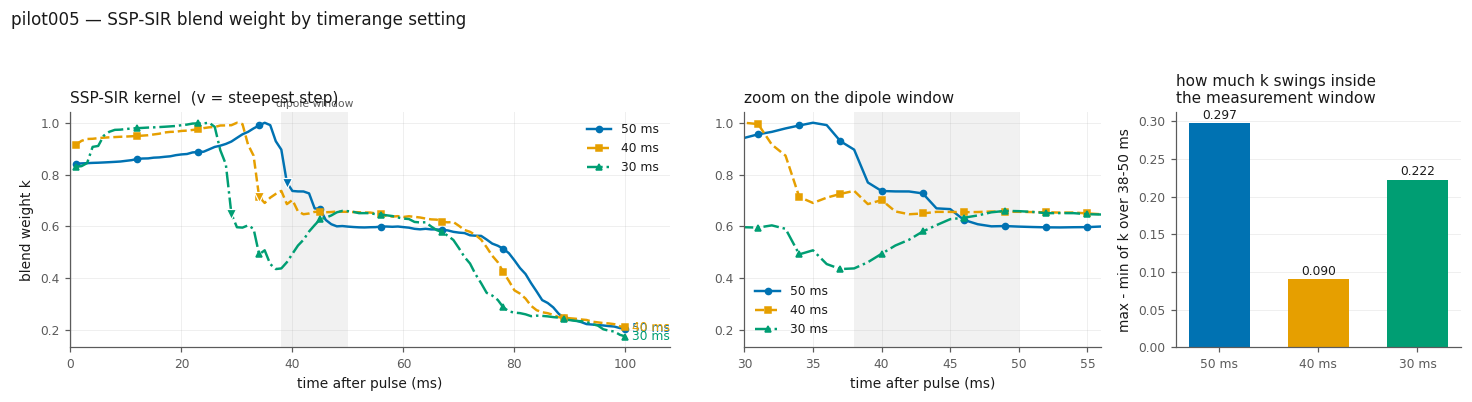

In [55]:
# ============================ FIGURE · the kernel at each setting ============================
def fig_kernel(subject):
    k = KERNEL[subject]
    fig, axes = plt.subplots(1, 3, figsize=(13.4, 3.5),
                             gridspec_kw=dict(width_ratios=[2.1, 1.25, 1.0]))
    t = POST_MS

    ax = axes[0]
    shade_dipole(ax, DIP_TMIN * 1e3, DIP_TMAX * 1e3, "dipole window")
    for T in SETTINGS:
        kern = k["ops"][T]["kernel"][0]
        ax.plot(t, kern, **t_style(T, markevery=11))
        i = int(np.argmax(np.abs(np.diff(kern))))
        ax.plot(t[i + 1], kern[i + 1], marker="v", ms=7, color=T_COLOR[T],
                mec="white", mew=0.8, ls="none", zorder=5)
        ax.annotate(f"{T} ms", xy=(t[-1], kern[-1]), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8, color=T_COLOR[T])
    ax.set_ylabel("blend weight k")
    ax.set_title("SSP-SIR kernel  (v = steepest step)", loc="left")
    ax.set_xlim(0, 108)
    ms_axis(ax)
    tidy(ax)

    ax = axes[1]
    shade_dipole(ax, DIP_TMIN * 1e3, DIP_TMAX * 1e3)
    for T in SETTINGS:
        kern = k["ops"][T]["kernel"][0]
        ax.plot(t, kern, **t_style(T, markevery=3))
    ax.set_xlim(30, 56)
    ax.set_title("zoom on the dipole window", loc="left")
    ms_axis(ax)
    tidy(ax)

    ax = axes[2]
    tab = KERNEL_TABLE[subject]
    x = np.arange(len(SETTINGS))
    ax.bar(x, [tab.loc[T, "k range 38-50"] for T in SETTINGS],
           color=[T_COLOR[T] for T in SETTINGS], width=0.62)
    for xi, T in zip(x, SETTINGS):
        v = tab.loc[T, "k range 38-50"]
        ax.annotate(f"{v:.3f}", xy=(xi, v), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8, color=INK)
    ax.set_xticks(x, [f"{T} ms" for T in SETTINGS])
    ax.set_ylabel("max - min of k over 38-50 ms")
    ax.set_title("how much k swings inside\nthe measurement window", loc="left")
    ax.grid(axis="x", visible=False)
    tidy(ax, legend=False)

    fig.suptitle(f"{subject} — SSP-SIR blend weight by timerange setting", x=0.005, ha="left",
                 fontsize=11, y=1.03)
    fig.tight_layout()
    return fig


FIGS = {}
for sub in SUBJECTS:
    FIGS[(sub, "kernel")] = fig_kernel(sub)
    plt.show()

---
## 2 · Three calibrations, run as they ran online

`Preprocessor.calibrate()` on the 125 saved `calibration_*_trial_raw.npy` buffers, then
`DipoleFitter.calibrate()` and `TEPNormalizer.calibrate()` — the sequence
`run_calibration()` in `2_intervention.py` performs. The only change is
`_cfg.ssp_sir_opts.timerange`; `_opts` is refreshed afterwards because `calibrate()` reads
the snapshot taken in `__init__`.

Everything upstream of SSP-SIR is *structurally* setting-independent — bad channels, the
interpolation, the ICA, the ocular thresholds and the SOUND filter are all computed before
SSP-SIR runs, on a survivor set fixed by the ocular and pre-MAD gates. The next cell
asserts that rather than assuming it, which is what licenses the shared-prefix replay in
section 4.

In [56]:
SESSION_OVERRIDES = {          # ocular z used online before commit f4fd395
    "pilot003": dict(ocular_z_threshold=2.0),
    "pilot004": dict(ocular_z_threshold=2.0),
}


def make_preprocessor(T, subject, bundle=None):
    pp = (Preprocessor(str(FORWARD_PATH)) if bundle is None
          else Preprocessor.from_bundle(bundle, str(FORWARD_PATH)))
    pp.keep_full_epochs = True                              # as Decider.__init__
    pp._cfg.ssp_sir_opts.timerange = ["automatic", int(T)]  # the one change
    ov = SESSION_OVERRIDES.get(subject, {})
    if "ocular_z_threshold" in ov:
        pp._cfg.trial_reject_opts.ocular.z_threshold = ov["ocular_z_threshold"]
    pp._opts = pp._cfg.to_dicts()                           # calibrate() reads this copy
    return pp


def run_calibration(T, subject):
    t0 = time.time()
    run_dir = SESS[subject]["dir"]
    stems = [p.name[: -len("_trial_raw.npy")]
             for p in sorted(run_dir.glob("calibration_*_trial_raw.npy"))]
    pp = make_preprocessor(T, subject)
    for stem in stems:
        x = np.load(run_dir / f"{stem}_trial_raw.npy")
        pp.add_trial(x, trial_times(CAL_TMIN, len(x)))
    log = io.StringIO()
    with contextlib.redirect_stdout(log):
        model_buffers, dipole_buffers = pp.calibrate()
        fitter = DipoleFitter(str(FORWARD_PATH))
        amps = fitter.calibrate(dipole_buffers)
        normalizer = TEPNormalizer()
        labels = normalizer.calibrate(amps)
    return dict(T=T, pp=pp, fitter=fitter, normalizer=normalizer,
                bundle=pp.calibration_params, fitting_info=fitter.fitting_info,
                dipole_buffers=dipole_buffers, model_buffers=model_buffers,
                amps=np.asarray(amps), labels=np.asarray(labels),
                n_cal=len(stems), log=log.getvalue(), seconds=time.time() - t0)


CAL = {}
for sub in SUBJECTS:
    CAL[sub] = {}
    for T in SETTINGS:
        CAL[sub][T] = run_calibration(T, sub)
        c = CAL[sub][T]
        print(f"{sub}  T={T:>2} ms : {c['seconds']:5.0f} s   "
              f"{len(c['bundle']['trials_kept'])} of {c['n_cal']} trials kept   "
              f"dipole window {c['fitting_info']['index_range']}")

pilot005  T=50 ms :    13 s   107 of 125 trials kept   dipole window (1, 5)
pilot005  T=40 ms :    11 s   107 of 125 trials kept   dipole window (0, 5)
pilot005  T=30 ms :    12 s   106 of 125 trials kept   dipole window (0, 5)


In [57]:
# ---------------- what the shared prefix requires, asserted rather than assumed
def assert_prefix_shared(subject):
    ref = CAL[subject][REFERENCE_T]["bundle"]
    for T in SETTINGS[1:]:
        b = CAL[subject][T]["bundle"]
        assert list(b["bad_channels"]) == list(ref["bad_channels"]), f"bad channels differ at T={T}"
        du = np.abs(b["ica"].unmixing_matrix_ - ref["ica"].unmixing_matrix_).max()
        ds = np.abs(b["sound_filter"] - ref["sound_filter"]).max()
        assert du == 0.0 and ds == 0.0, f"ICA/SOUND differ at T={T}: {du:.2e} / {ds:.2e}"
        assert set(b["ocular_threshold_post"]) == set(ref["ocular_threshold_post"])
        for key in ("ocular", "qc"):
            assert np.array_equal(b["trials_dropped"][key], ref["trials_dropped"][key]), \
                f"{key} drops differ at T={T} — the prefix is not shared"
    print(f"{subject}: bad channels, ICA, SOUND filter, ocular thresholds and the "
          f"ocular/pre-MAD drops are identical across all settings (exact equality)")


def calibration_table(subject):
    s = SESS[subject]
    fwd = mne.read_forward_solution(str(FORWARD_PATH), verbose=False).pick_channels(
        CAL[subject][REFERENCE_T]["fitter"]._forward.ch_names, ordered=True)
    rr = CAL[subject][REFERENCE_T]["fitter"]._forward["source_rr"]
    ref = CAL[subject][REFERENCE_T]
    online_fi = s["online"]["dipole"]

    rows = []
    for T in SETTINGS:
        c = CAL[subject][T]
        b, fi = c["bundle"], c["fitting_info"]
        ir = fi["index_range"]
        w0 = DIP_TMIN * 1e3 + int(ir[0])
        w1 = DIP_TMIN * 1e3 + int(ir[1]) - 1
        pos, ori = fi["position_index"], np.asarray(fi["orientation"], float)
        rpos, rori = ref["fitting_info"]["position_index"], np.asarray(ref["fitting_info"]["orientation"], float)
        dmm = float(np.linalg.norm(rr[pos] - rr[rpos]) * 1e3)
        ang = float(np.degrees(np.arccos(np.clip(
            abs(np.dot(ori, rori) / (np.linalg.norm(ori) * np.linalg.norm(rori))), -1, 1))))
        kern = b["sspsir_filter_kernel"][0]
        in_dip = (POST_MS >= DIP_TMIN * 1e3) & (POST_MS <= DIP_TMAX * 1e3)
        rows.append({
            "T (ms)": T,
            "kept": len(b["trials_kept"]),
            "drop ocular": len(b["trials_dropped"]["ocular"]),
            "drop preMAD": len(b["trials_dropped"]["qc"]),
            "drop postMAD": len(b["trials_dropped"]["post"]),
            "vertex": int(pos),
            "d vertex (mm)": round(dmm, 1),
            "d orient (deg)": round(ang, 1),
            "dipole win (ms)": f"{w0:.0f}-{w1:.0f}",
            "k mean 38-50": round(float(kern[in_dip].mean()), 4),
            "cal TEP median": f"{np.median(c['amps']):.4f}",
            "cal TEP SD": f"{c['amps'].std(ddof=1):.4f}",
            "norm cal_std": f"{c['normalizer']._cal_std:.4f}",
            "seconds": round(c["seconds"]),
        })
    tab = pd.DataFrame(rows).set_index("T (ms)")
    tab.attrs["online_vertex"] = online_fi.get("position_index")
    return tab


CAL_TABLE = {}
for sub in SUBJECTS:
    assert_prefix_shared(sub)
    CAL_TABLE[sub] = calibration_table(sub)
    print(f"\n=== {sub} — calibration outcome by setting "
          f"(vertex/orientation shifts are vs T={REFERENCE_T}) ===")
    print(CAL_TABLE[sub].to_string())
    ov = CAL_TABLE[sub].attrs["online_vertex"]
    got = CAL_TABLE[sub].loc[REFERENCE_T, "vertex"]
    print(f"\ncontrol check: online vertex {ov}  vs replayed T={REFERENCE_T} vertex {got}"
          f"   {'MATCH' if ov == got else 'DIFFER — read the shifts against replay noise, not zero'}")

pilot005: bad channels, ICA, SOUND filter, ocular thresholds and the ocular/pre-MAD drops are identical across all settings (exact equality)

=== pilot005 — calibration outcome by setting (vertex/orientation shifts are vs T=50) ===
        kept  drop ocular  drop preMAD  drop postMAD  vertex  d vertex (mm)  d orient (deg) dipole win (ms)  k mean 38-50 cal TEP median cal TEP SD norm cal_std  seconds
T (ms)                                                                                                                                                                   
50       107           13            4             1    4641            0.0             0.0           39-42        0.6898         0.0298     0.0203       0.0208       13
40       107           13            4             1    8135            7.5             8.3           38-42        0.6669         0.0377     0.0246       0.0253       11
30       106           13            4             2     377           12.5            1

---
## 3 · A yardstick for the dipole shifts

The session's dipole is unstable under resampling alone, so "the vertex moved 20 mm" means
nothing without the spread it moves in by chance. This bootstraps the reference
calibration's own dipole buffers — same data, same code, resampled trials — and reports
each setting's shift as a percentile of that null.

`BOOTSTRAP_N = 0` skips it; the shifts are then printed without a reference distribution.

In [58]:
def dipole_bootstrap(subject, n=BOOTSTRAP_N, seed=BOOTSTRAP_SEED):
    if not n:
        return None
    ref = CAL[subject][REFERENCE_T]
    buf = np.asarray(ref["dipole_buffers"])
    rr = ref["fitter"]._forward["source_rr"]
    pos0 = ref["fitting_info"]["position_index"]
    ori0 = np.asarray(ref["fitting_info"]["orientation"], float)
    rng = np.random.default_rng(seed)

    t0 = time.time()
    probe = DipoleFitter(str(FORWARD_PATH))
    with contextlib.redirect_stdout(io.StringIO()):
        probe.calibrate(buf[rng.integers(0, len(buf), len(buf))])
    per = time.time() - t0
    print(f"{subject}: ~{per:.2f} s per resample -> ~{per * n / 60:.1f} min for n={n}")

    dmm, dang, same = [], [], 0
    for _ in range(n):
        idx = rng.integers(0, len(buf), len(buf))
        f = DipoleFitter(str(FORWARD_PATH))
        with contextlib.redirect_stdout(io.StringIO()):
            f.calibrate(buf[idx])
        fi = f.fitting_info
        p, o = fi["position_index"], np.asarray(fi["orientation"], float)
        dmm.append(np.linalg.norm(rr[p] - rr[pos0]) * 1e3)
        dang.append(np.degrees(np.arccos(np.clip(
            abs(np.dot(o, ori0) / (np.linalg.norm(o) * np.linalg.norm(ori0))), -1, 1))))
        same += int(p == pos0)
    return dict(dmm=np.asarray(dmm), dang=np.asarray(dang), same_vertex=same / n, n=n,
                seconds=time.time() - t0)


BOOT = {sub: dipole_bootstrap(sub) for sub in SUBJECTS}

for sub, bt in BOOT.items():
    tab = CAL_TABLE[sub]
    if bt is None:
        print(f"{sub}: bootstrap skipped")
        continue
    q = lambda a, v: float((a <= v).mean() * 100)
    print(f"\n{sub}: resampling the reference calibration ({bt['n']} draws, "
          f"{bt['seconds']/60:.1f} min)")
    print(f"  vertex shift under resampling alone: median {np.median(bt['dmm']):.1f} mm, "
          f"95th pct {np.percentile(bt['dmm'], 95):.1f} mm, same vertex in {bt['same_vertex']*100:.0f}% of draws")
    print(f"  orientation change: median {np.median(bt['dang']):.1f} deg, "
          f"95th pct {np.percentile(bt['dang'], 95):.1f} deg")
    for T in SETTINGS[1:]:
        dm, da = tab.loc[T, "d vertex (mm)"], tab.loc[T, "d orient (deg)"]
        print(f"  T={T:>2}: vertex {dm:5.1f} mm = {q(bt['dmm'], dm):4.0f}th pct of the null   |   "
              f"orientation {da:5.1f} deg = {q(bt['dang'], da):4.0f}th pct")
    print("  a shift below ~the 95th percentile is within what resampling alone produces")

pilot005: ~0.89 s per resample -> ~7.4 min for n=500

pilot005: resampling the reference calibration (500 draws, 7.5 min)
  vertex shift under resampling alone: median 12.9 mm, 95th pct 21.6 mm, same vertex in 3% of draws
  orientation change: median 10.8 deg, 95th pct 21.5 deg
  T=40: vertex   7.5 mm =   35th pct of the null   |   orientation   8.3 deg =   34th pct
  T=30: vertex  12.5 mm =   49th pct of the null   |   orientation  10.6 deg =   48th pct
  a shift below ~the 95th percentile is within what resampling alone produces


---
## 4 · Replaying the single trials

Every arm is replayed through each setting's calibration. Because section 2 asserted that
everything up to and including SOUND is identical across settings, the replay splits in two:

- **prefix** — resample, baseline, artifact window, interpolation, average reference, the
  ocular check, ICA, baseline, average reference, crop to [1, 100] ms, SOUND. Computed
  **once per trial**. This is the expensive part (`ica.apply` dominates).
- **tail** — SSP-SIR, artifact window 2, average reference, the global and local MAD gates,
  the dipole crop. Computed **once per trial per setting**, and cheap.

That makes the three arms differ *only* in SSP-SIR by construction, and costs roughly a
third of running the whole chain three times. The next cell proves the split is exact
against the unmodified `Preprocessor.preprocess_post` before the main loop uses it.

The two MAD gates run *after* SSP-SIR, so they are the one place where the settings can
disagree about which trials survive. Each setting is gated on its own calibration
statistics, and the primary comparisons below use only trials accepted by **all three**, so
a waveform difference is never a trial-selection difference in disguise.

In [59]:
WINDOWS_MS = {"early": (1, 15), "mid": (15, 38), "late": (60, 100)}
WIN_SL = {k: slice(int(round(a - POST_MS[0])), int(round(b - POST_MS[0])) + 1)
          for k, (a, b) in WINDOWS_MS.items()}
HF_B, HF_A = butter(2, 100.0 / (PROC_SFREQ / 2), btype="high")


def gfp(x):
    return np.sqrt((x ** 2).mean(axis=0))


def win_rms(x, sl):
    return float(np.sqrt((x[:, sl] ** 2).mean()))


def hf_rms(x, sl):
    return win_rms(filtfilt(HF_B, HF_A, x, axis=-1), sl)


def dipole_stats(fitter, epoch, info, dip_slice):
    """Free/fixed amplitude and the R^2 of the sample the fit selects.

    The same helper as scripts_analysis/sound_sspsir_performance.py. index_range is
    relative to the dipole crop, exactly as DipoleFitter.fit_trial uses it.
    """
    L = fitter._forward["sol"]["data"]
    L = L - L.mean(axis=0)
    p = info["position_index"] * 3
    Lp = L[:, p: p + 3]
    s, e = info["index_range"]
    seg = epoch[:, dip_slice][:, s:e]
    pinv, Lori = np.linalg.pinv(Lp), Lp @ info["orientation"]
    best = {"amp_free": np.nan, "r2_free": -np.inf, "amp_fixed": np.nan, "r2_fixed": -np.inf}
    for k in range(seg.shape[1]):
        y = seg[:, k]
        denom = ((y - y.mean()) ** 2).sum()
        if denom <= 0:
            continue
        Q = pinv @ y
        r2 = 1 - ((y - Lp @ Q) ** 2).sum() / denom
        if r2 > best["r2_free"]:
            best["r2_free"], best["amp_free"] = r2, float(np.linalg.norm(Q))
        a = float(Lori @ y / (Lori @ Lori))
        r2f = 1 - ((y - Lp @ (info["orientation"] * a)) ** 2).sum() / denom
        if r2f > best["r2_fixed"]:
            best["r2_fixed"], best["amp_fixed"] = r2f, abs(a)
    for key in ("r2_free", "r2_fixed"):
        if best[key] == -np.inf:
            best[key] = np.nan
    return best


def make_tail(pp_T):
    """SSP-SIR onward, transcribed from Preprocessor.preprocess_post."""
    cp, cfg, opts = pp_T._calibration_params, pp_T._cfg, pp_T._opts
    g_thr = opts["trial_reject_opts"]["post"]["global_zscore_threshold"]
    l_thr = opts["trial_reject_opts"]["post"]["local_zscore_threshold"]
    stats = cp["good_trial_stats_post"]

    def tail(ep_sound, ocular):
        data = ssp_sir_single_trial(
            ep_sound.get_data(copy=True)[0],
            cp["sspsir_suppression_matrix_P"],
            cp["sspsir_sir_projmat_suppr"],
            cp["sspsir_sir_projmat_orig"],
            cp["sspsir_filter_kernel"],
        )
        sspsir = data.copy()
        ep = mne.EpochsArray(data.reshape(1, *data.shape), ep_sound.info,
                             events=ep_sound.events, tmin=ep_sound.times[0], verbose=False)
        ep = mne.preprocessing.fix_stim_artifact(
            ep, tmin=pp_T._post_tmin, tmax=cfg.artifact_window_2[1], mode="window")
        ep.set_eeg_reference("average", projection=False, verbose=False)
        final = ep.get_data(copy=True)[0]

        reject = ep.copy().crop(cfg.reject_range[0], cfg.reject_range[1]).get_data(copy=True)
        mad_val = median_abs_deviation(reject, axis=(1, 2))[0]
        z_mad = float((mad_val - stats["mads_mean"]) / stats["mads_std"])
        reason = None
        if ocular:
            reason = "ocular"
        elif z_mad < g_thr[0] or z_mad > g_thr[1]:
            reason = "global_mad"
        else:
            z_local = zscore(median_abs_deviation(reject, axis=2), axis=1)
            if np.any(np.abs(z_local) > l_thr):
                reason = "local_mad"
        dip = ep.copy().crop(pp_T._dipole_tmin, pp_T._dipole_tmax,
                             include_tmax=True).get_data(copy=True)[0]
        return dict(sspsir=sspsir, final=final, reason=reason, z_mad=z_mad,
                    dip=np.ascontiguousarray(dip, dtype=np.float64))

    return tail

In [60]:
# ---------------- the split path must equal the unmodified preprocess_post, exactly
def validate_split(subject, n=N_VALIDATE):
    run_dir = SESS[subject]["dir"]
    stems = SESS[subject]["arms"]["stem"].tolist()[:n]
    ref_pp = CAL[subject][REFERENCE_T]["pp"]
    tails = {T: make_tail(CAL[subject][T]["pp"]) for T in SETTINGS}

    worst = {T: dict(final=0.0, dip=0.0, reason_ok=0, n=0) for T in SETTINGS}
    for stem in stems:
        raw = np.load(run_dir / f"{stem}_post_raw.npy")
        times = trial_times(ref_pp._post_initial_tmin, len(raw))
        ep_sound, _, _, _, ocular = post_sound_chain(ref_pp, ref_pp._calibration_params, raw)
        for T in SETTINGS:
            pp_T = CAL[subject][T]["pp"]
            got = pp_T.preprocess_post(raw.copy(), times)          # the online method
            mine = tails[T](ep_sound, ocular)                      # the split path
            w = worst[T]
            w["n"] += 1
            w["final"] = max(w["final"], float(np.abs(pp_T.last_post_full - mine["final"]).max()))
            if got is None and mine["reason"] is None:
                raise AssertionError(f"{stem} T={T}: method rejected, split accepted")
            if got is not None:
                w["dip"] = max(w["dip"], float(np.abs(got - mine["dip"]).max()))
            w["reason_ok"] += int(pp_T.last_post_reject_reason == mine["reason"])
    return worst


for sub in SUBJECTS:
    print(f"{sub}: split-path check on {min(N_VALIDATE, len(SESS[sub]['arms']))} trials")
    for T, w in validate_split(sub).items():
        print(f"  T={T:>2}: max|d final| = {w['final']:.3e}   max|d dipole crop| = {w['dip']:.3e}   "
              f"reject reason identical {w['reason_ok']}/{w['n']}")
        assert w["final"] == 0.0 and w["dip"] == 0.0 and w["reason_ok"] == w["n"], \
            f"split path is not identical to preprocess_post at T={T}"
    print("  identical -> the shared prefix is used for the full replay")

pilot005: split-path check on 25 trials
  T=50: max|d final| = 0.000e+00   max|d dipole crop| = 0.000e+00   reject reason identical 25/25
  T=40: max|d final| = 0.000e+00   max|d dipole crop| = 0.000e+00   reject reason identical 25/25
  T=30: max|d final| = 0.000e+00   max|d dipole crop| = 0.000e+00   reject reason identical 25/25
  identical -> the shared prefix is used for the full replay


In [61]:
def replay_session(subject):
    """One pass over every trial: prefix once, then each setting's tail."""
    run_dir = SESS[subject]["dir"]
    arms = SESS[subject]["arms"]
    ref_pp = CAL[subject][REFERENCE_T]["pp"]
    ref_cp = ref_pp._calibration_params
    tails = {T: make_tail(CAL[subject][T]["pp"]) for T in SETTINGS}
    fitters = {T: CAL[subject][T]["fitter"] for T in SETTINGS}
    fitinfo = {T: CAL[subject][T]["fitting_info"] for T in SETTINGS}
    ref_fitter, ref_fi = fitters[REFERENCE_T], fitinfo[REFERENCE_T]

    rows = []
    store = {}          # (arm, T, stage) -> list of (n_ch, n_times) float32
    shared = {}         # (arm, stage)    -> list, for stages that do not depend on T
    long_ms = None
    t0 = time.time()

    for i, r in enumerate(arms.itertuples(index=False), 1):
        if i % 100 == 0 or i == len(arms):
            el = time.time() - t0
            print(f"  {i}/{len(arms)}  {el/60:.1f} min  (~{el/i*len(arms)/60:.1f} min total)", flush=True)
        raw = np.load(run_dir / f"{r.stem}_post_raw.npy")
        ep_sound, _, pre_long, lms, ocular = post_sound_chain(ref_pp, ref_cp, raw)
        long_ms = lms
        sound = ep_sound.get_data(copy=True)[0]
        shared.setdefault((r.arm, "pre_sound_long"), []).append(pre_long.astype(np.float32))
        shared.setdefault((r.arm, "sound"), []).append(sound.astype(np.float32))

        for T in SETTINGS:
            out = tails[T](ep_sound, ocular)
            fin = out["final"]
            store.setdefault((r.arm, T, "sspsir"), []).append(out["sspsir"].astype(np.float32))
            store.setdefault((r.arm, T, "final"), []).append(fin.astype(np.float32))

            amp = float(fitters[T].fit_trial(out["dip"]))
            own = dipole_stats(fitters[T], fin, fitinfo[T], DIP_SL)
            fix = dipole_stats(ref_fitter, fin, ref_fi, DIP_SL)
            ir = fitinfo[T]["index_range"]
            n45 = slice(DIP_SL.start + ir[0], DIP_SL.start + ir[1])
            rows.append({
                "subject": subject, "stem": r.stem, "arm": r.arm, "T": T,
                "trial_index": i - 1,
                "reason": out["reason"], "accepted": out["reason"] is None,
                "ocular": ocular, "z_mad": out["z_mad"],
                "amp": amp,
                "amp_free": own["amp_free"], "r2_free": own["r2_free"],
                "amp_fixed": own["amp_fixed"], "r2_fixed": own["r2_fixed"],
                "amp_refdip": fix["amp_free"], "r2_refdip": fix["r2_free"],
                "rms_own_n45": win_rms(fin, n45),
                "rms_fixed_n45": win_rms(fin, DIP_SL),
                "norm_late": win_rms(fin, WIN_SL["late"]),
                # 1-15 ms is blanked by both fix_stim_artifact calls (measured: samples
                # 1-12 ms are exactly 0), so the muscle proxy is taken over 15-38 ms --
                # after the blank, before the dipole window.
                "hf_mid": hf_rms(fin, WIN_SL["mid"]),
                "hf_n45": hf_rms(fin, DIP_SL),
                "rms_mid": win_rms(fin, WIN_SL["mid"]),
                "hf_early_blanked": hf_rms(out["sspsir"], WIN_SL["early"]),
                "online_reason": getattr(r, "post_reject_reason", np.nan),
                "online_amp": getattr(r, "tep_amplitude_raw", np.nan),
            })

    df = pd.DataFrame(rows)
    ev = {k: np.stack(v) for k, v in store.items()}
    sh = {k: np.stack(v) for k, v in shared.items()}
    print(f"  done in {(time.time()-t0)/60:.1f} min; "
          f"epoch store {(sum(a.nbytes for a in ev.values())+sum(a.nbytes for a in sh.values()))/1e6:.0f} MB")
    return df, ev, sh, long_ms


TRIALS, EPOCHS, SHARED, LONG_MS = {}, {}, {}, {}
for sub in SUBJECTS:
    print(f"\n{sub}: replaying {len(SESS[sub]['arms'])} trials x {len(SETTINGS)} settings")
    TRIALS[sub], EPOCHS[sub], SHARED[sub], LONG_MS[sub] = replay_session(sub)


pilot005: replaying 945 trials x 3 settings
  100/945  0.2 min  (~1.7 min total)
  200/945  0.4 min  (~1.7 min total)
  300/945  0.5 min  (~1.7 min total)
  400/945  0.7 min  (~1.7 min total)
  500/945  0.9 min  (~1.7 min total)
  600/945  1.1 min  (~1.8 min total)
  700/945  1.3 min  (~1.8 min total)
  800/945  1.5 min  (~1.8 min total)
  900/945  1.7 min  (~1.8 min total)
  945/945  1.8 min  (~1.8 min total)
  done in 1.8 min; epoch store 188 MB


In [62]:
# ---------------- acceptance, and the shared trial set the comparisons run on
def acceptance(subject):
    df = TRIALS[subject]
    piv = df.pivot_table(index=["arm", "stem"], columns="T", values="accepted")
    shared_ok = piv.all(axis=1)
    SESS[subject]["shared_accepted"] = set(shared_ok[shared_ok].index.get_level_values("stem"))

    tab = (df.groupby(["arm", "T"])
             .agg(n=("accepted", "size"), accepted=("accepted", "sum"))
             .reset_index()
             .pivot(index="arm", columns="T", values="accepted"))
    tab.columns = [f"accepted T={c}" for c in tab.columns]
    tab["n trials"] = df.groupby("arm")["stem"].nunique()
    tab["accepted by all"] = shared_ok.groupby("arm").sum()
    reasons = (df[~df["accepted"]].groupby(["T", "reason"]).size()
                 .unstack(fill_value=0))
    return tab, reasons


for sub in SUBJECTS:
    tab, reasons = acceptance(sub)
    print(f"\n=== {sub} — trials surviving the post-SSP-SIR gates ===")
    print(tab.to_string())
    print(f"\nrejection reasons by setting:")
    print(reasons.to_string())
    df = TRIALS[sub]
    on = df[(df["T"] == REFERENCE_T) & df["online_reason"].notna()]
    if len(on):
        agree = ((on["online_reason"].fillna("none") == on["reason"].fillna("none")).mean())
        pair = on[["online_amp", "amp"]].dropna()
        damp = (pair["online_amp"] - pair["amp"]).abs().max() if len(pair) else np.nan
        print(f"\ncontrol check vs the online log ({len(on)} intervention trials): "
              f"reject reason agrees {agree*100:.1f}%, "
              f"max|d amplitude| = {damp:.2e} over {len(pair)} trials with a logged amplitude")


=== pilot005 — trials surviving the post-SSP-SIR gates ===
                      accepted T=30  accepted T=40  accepted T=50  n trials  accepted by all
arm                                                                                         
baseline                         83             83             83       100               83
calibration                     110            111            111       125              110
evaluation                      345            344            343       400              342
predetermined_single             76             73             74        80               73
prime_single_pulse              220            221            221       240              220

rejection reasons by setting:
reason  global_mad  local_mad  ocular
T                                    
30               1          3     107
40               1          5     107
50               1          5     107

control check vs the online log (25 intervention trials): reject re

---
## 5 · Stage by stage: raw, after SOUND, after SSP-SIR

Grand averages over the trials **accepted at all three settings**, so the only thing that
differs between the coloured traces is SSP-SIR.

The left panel is the pre-SOUND epoch over its full online extent, [-30, 100] ms: that
epoch genuinely exists in `preprocess_post` before the crop, so no value in it is invented.
SOUND and SSP-SIR are shown only over [1, 100] ms, which is all they are applied to online —
`sspsir_filter_kernel` is one weight per sample of that window and has no pre-pulse values,
so the later stages are not extended. `fix_stim_artifact` zeroes [-14, +14] ms, and the
polyphase resample smears the pulse backwards from about -9 ms, so the only genuinely
measured pre-pulse signal is roughly [-30, -10] ms; it is marked.

Stages that are shared across settings are drawn in neutral grey, so colour always means
"setting".

**Units.** The processed epochs carry µV-scale numbers directly (a grand average peaks
around 25-30), which MNE holds in its volts field without rescaling. No conversion factor
is applied anywhere in this notebook: field values are µV as stored, and `fit_trial`
amplitudes are µA·m as stored — the same convention as
`scripts_analysis/sound_sspsir_performance.py`.

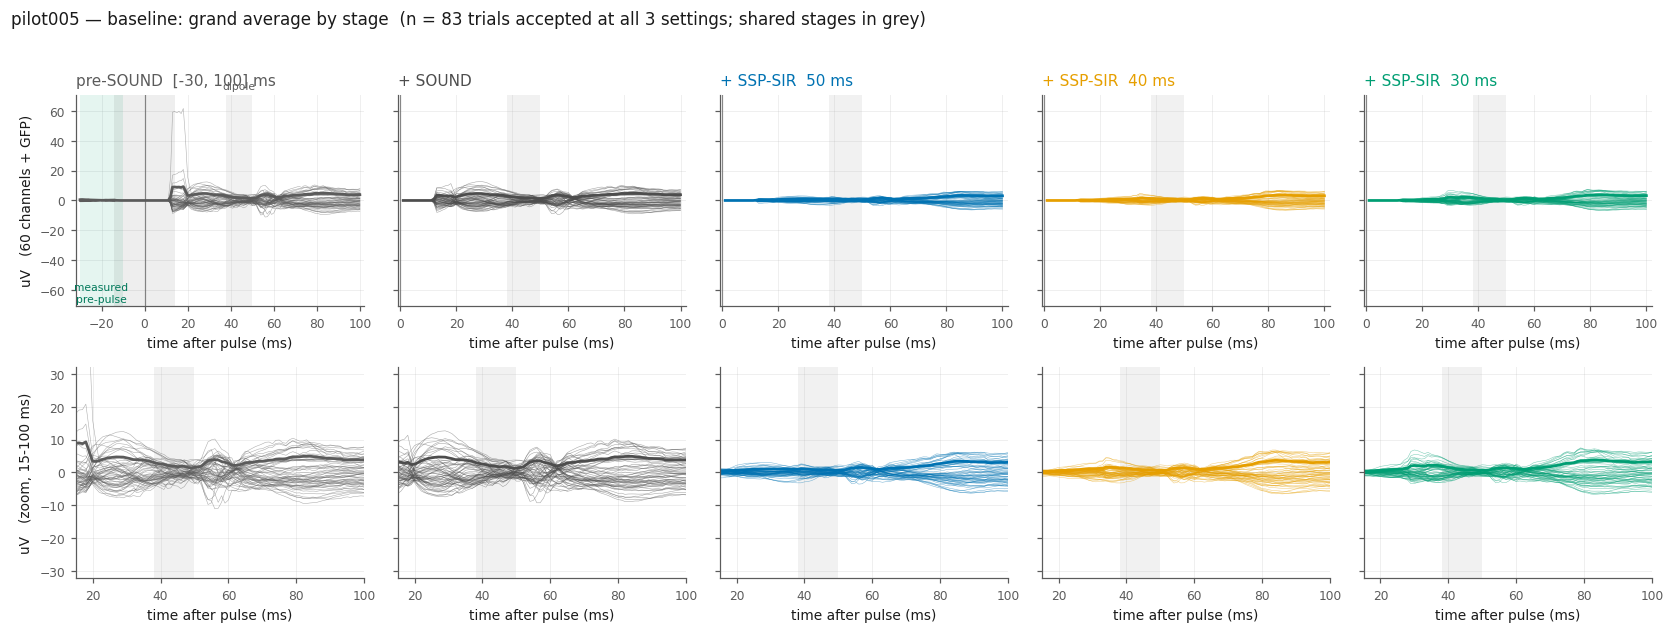

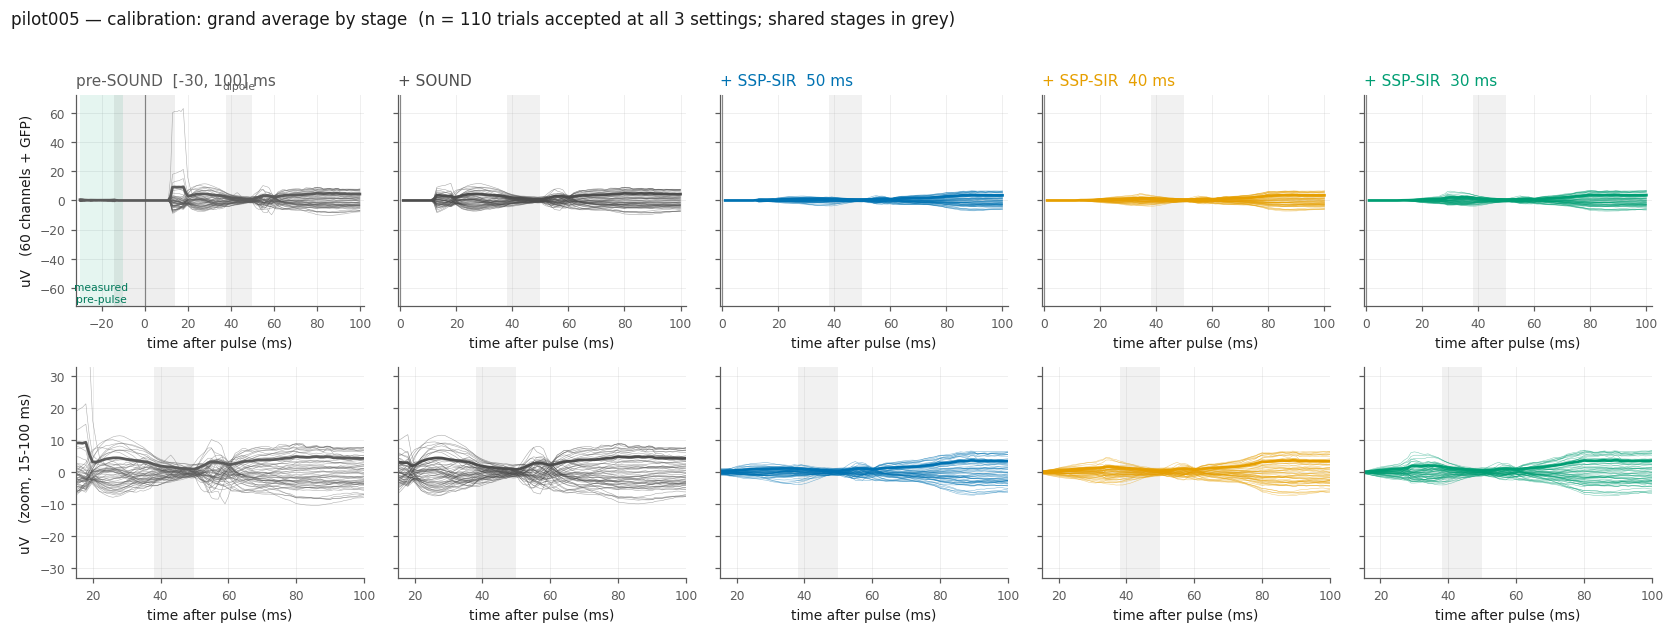

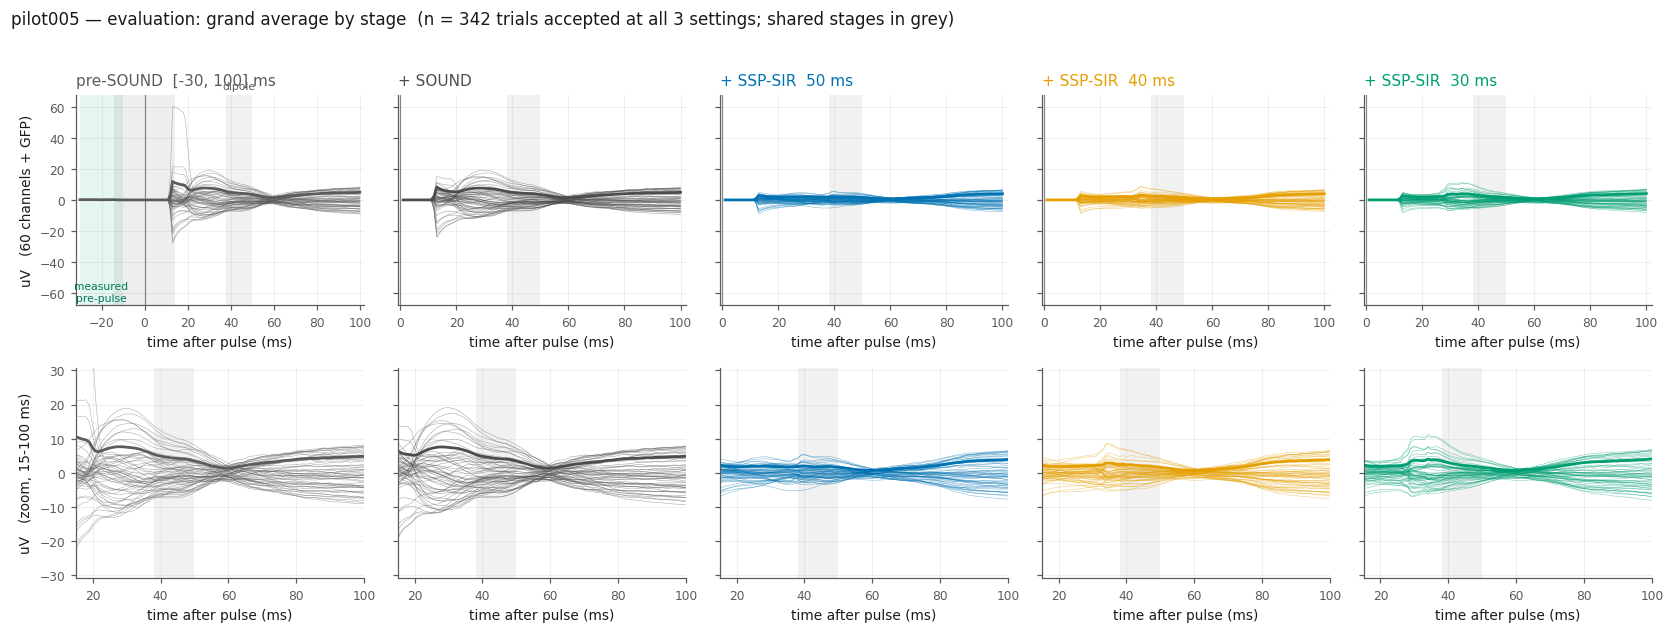

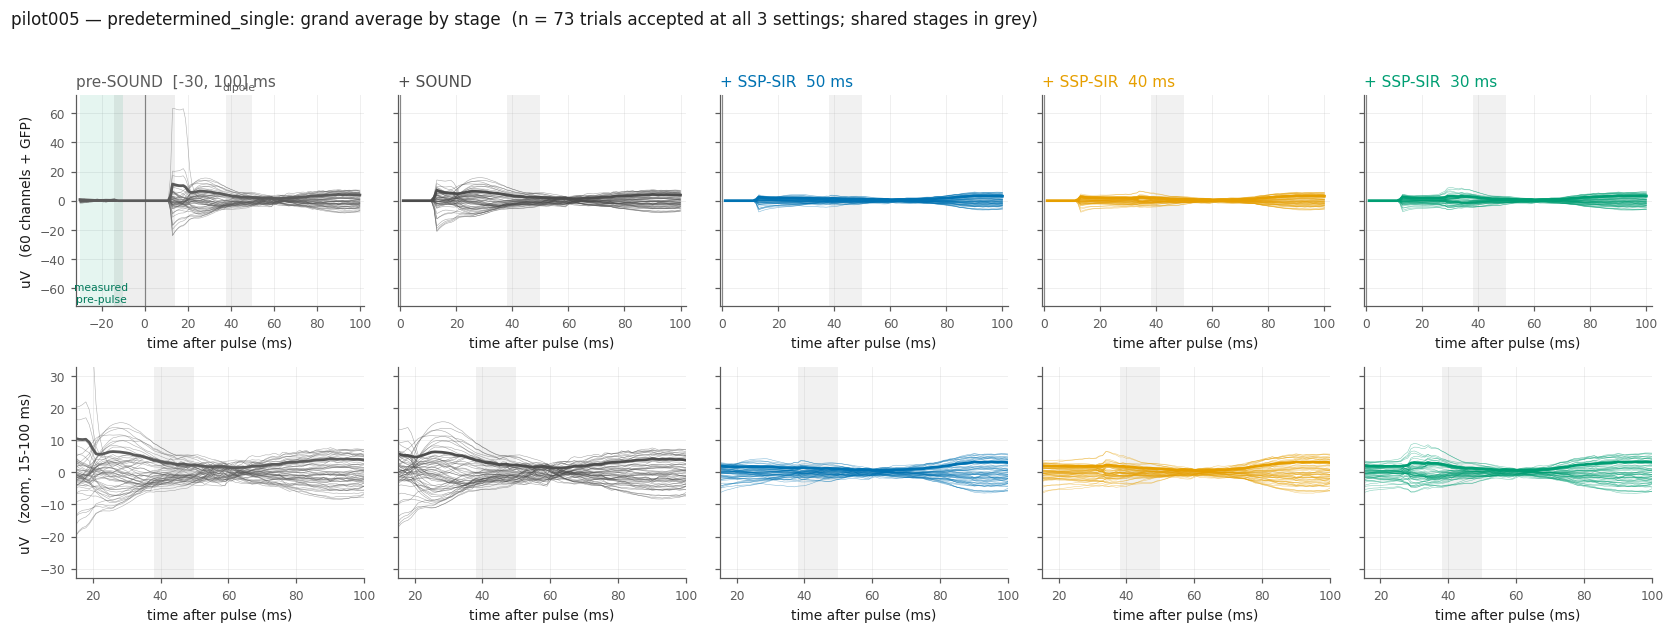

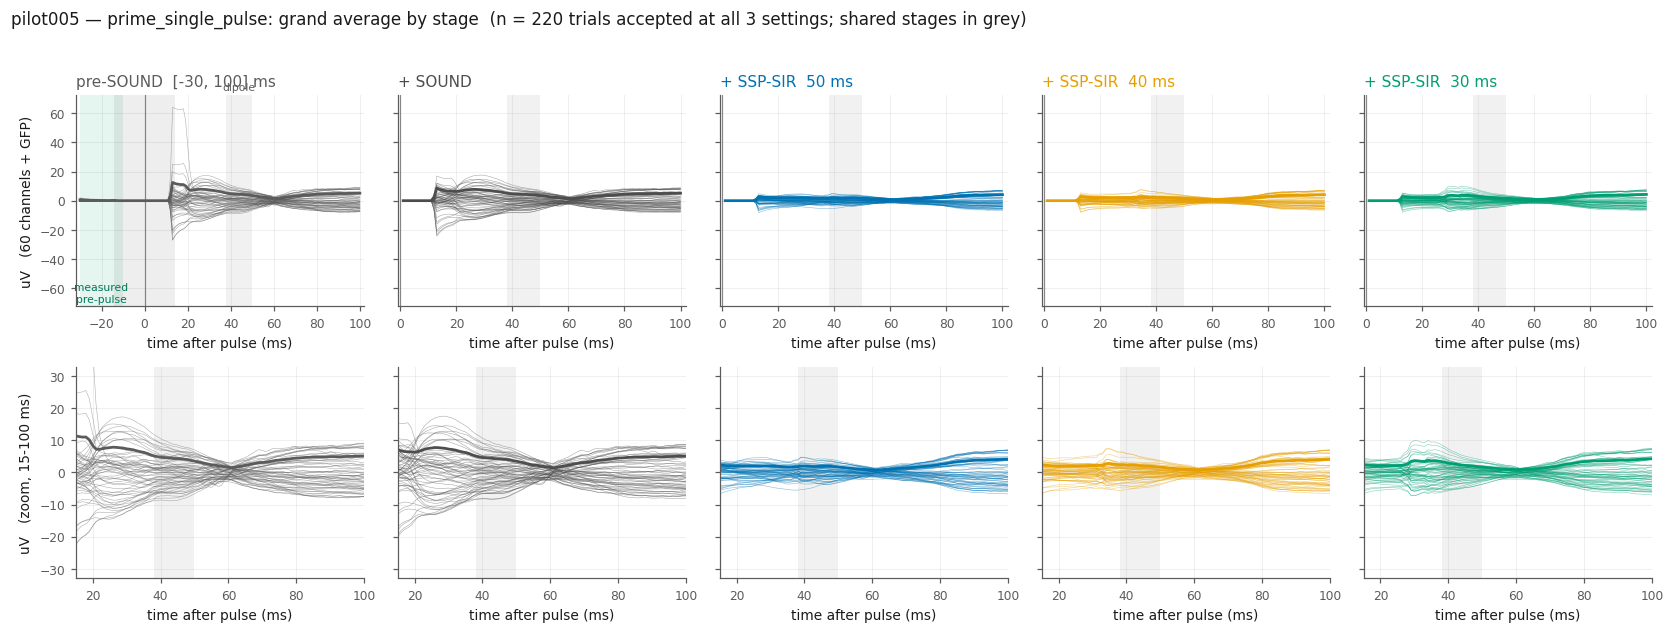

In [63]:
def arm_epochs(subject, arm, T, stage, accepted_only=True, stems=None):
    """Stack of trials for one arm/setting/stage, restricted to a trial set."""
    df = TRIALS[subject]
    sel = df[(df["arm"] == arm) & (df["T"] == T)].reset_index(drop=True)
    if stage in ("pre_sound_long", "sound"):
        arr = SHARED[subject][(arm, stage)]
    else:
        arr = EPOCHS[subject][(arm, T, stage)]
    if stems is not None:
        mask = sel["stem"].isin(stems).to_numpy()
    elif accepted_only:
        mask = sel["stem"].isin(SESS[subject]["shared_accepted"]).to_numpy()
    else:
        mask = np.ones(len(sel), bool)
    return arr[mask]


def pre_sound_short(subject, arm, **kw):
    """The [1, 100] ms part of the stored [-30, 100] ms pre-SOUND epoch."""
    lms = LONG_MS[subject]
    i0 = int(np.where(lms == POST_MS[0])[0][0])
    return arm_epochs(subject, arm, SETTINGS[0], "pre_sound_long", **kw)[:, :, i0: i0 + len(POST_MS)]


def fig_stages(subject, arm):
    lms = LONG_MS[subject]
    n_panels = 2 + len(SETTINGS)
    fig, axes = plt.subplots(2, n_panels, figsize=(3.05 * n_panels, 5.6), sharey="row")

    long_ev = arm_epochs(subject, arm, SETTINGS[0], "pre_sound_long").mean(axis=0)
    short = {"pre_sound": pre_sound_short(subject, arm),
             "sound": arm_epochs(subject, arm, SETTINGS[0], "sound")}
    for T in SETTINGS:
        short[T] = arm_epochs(subject, arm, T, "sspsir")

    panels = [("pre-SOUND  [-30, 100] ms", long_ev, lms, MUTED),
              ("+ SOUND", short["sound"].mean(axis=0), POST_MS, "#4d4d4d")]
    panels += [(f"+ SSP-SIR  {T} ms", short[T].mean(axis=0), POST_MS, T_COLOR[T]) for T in SETTINGS]

    vmax = max(np.abs(p[1][:, p[2] >= 15]).max() for p in panels) * 1.15
    for j, (title, ev, tt, col) in enumerate(panels):
        ax = axes[0, j]
        if j == 0:
            ax.axvspan(-30, -10, color="#009E73", alpha=0.10, lw=0)
            ax.annotate("measured\npre-pulse", xy=(-20, 0.02), xycoords=("data", "axes fraction"),
                        ha="center", fontsize=7, color="#00795a")
            ax.axvspan(-14, 14, color=INK, alpha=0.07, lw=0)
        shade_dipole(ax, DIP_TMIN * 1e3, DIP_TMAX * 1e3, "dipole" if j == 0 else None)
        ax.plot(tt, ev.T, lw=0.35, color=col, alpha=0.5)
        ax.plot(tt, gfp(ev), lw=1.8, color=col)
        ax.set_title(title, loc="left", color=col)
        ax.set_ylim(-vmax, vmax)
        ms_axis(ax, tt[0] - 2, tt[-1] + 2)
        if j == 0:
            ax.set_ylabel("uV   (60 channels + GFP)")
        tidy(ax, legend=False)

        ax = axes[1, j]
        shade_dipole(ax, DIP_TMIN * 1e3, DIP_TMAX * 1e3)
        ax.plot(tt, ev.T, lw=0.35, color=col, alpha=0.5)
        ax.plot(tt, gfp(ev), lw=1.8, color=col)
        ax.set_xlim(15, 100)
        ax.set_ylim(-vmax / 2.2, vmax / 2.2)
        ms_axis(ax)
        if j == 0:
            ax.set_ylabel("uV   (zoom, 15-100 ms)")
        tidy(ax, legend=False)

    n = len(SESS[subject]["shared_accepted"] & set(TRIALS[subject].query("arm == @arm")["stem"]))
    fig.suptitle(f"{subject} — {arm}: grand average by stage  (n = {n} trials accepted at all "
                 f"{len(SETTINGS)} settings; shared stages in grey)",
                 x=0.005, ha="left", fontsize=11, y=1.02)
    fig.tight_layout()
    return fig


ARM_ORDER = ["baseline", "calibration", "evaluation", "predetermined_single", "prime_single_pulse"]
for sub in SUBJECTS:
    present = [a for a in ARM_ORDER if a in set(TRIALS[sub]["arm"])]
    SESS[sub]["arm_order"] = present
    for arm in present:
        FIGS[(sub, f"stages_{arm}")] = fig_stages(sub, arm)
        plt.show()

---
## 6 · Topography of the dipole time window

Two rows, because window and processing are otherwise confounded:

- **own window** — each setting's own recalibrated dipole window, which is what its
  amplitudes are actually measured in;
- **fixed 38-50 ms** — the configured window, identical for all three, so any difference is
  the processing alone.

One symmetric colour scale is shared by every map in the figure; a per-panel scale would
make three different fields look alike.

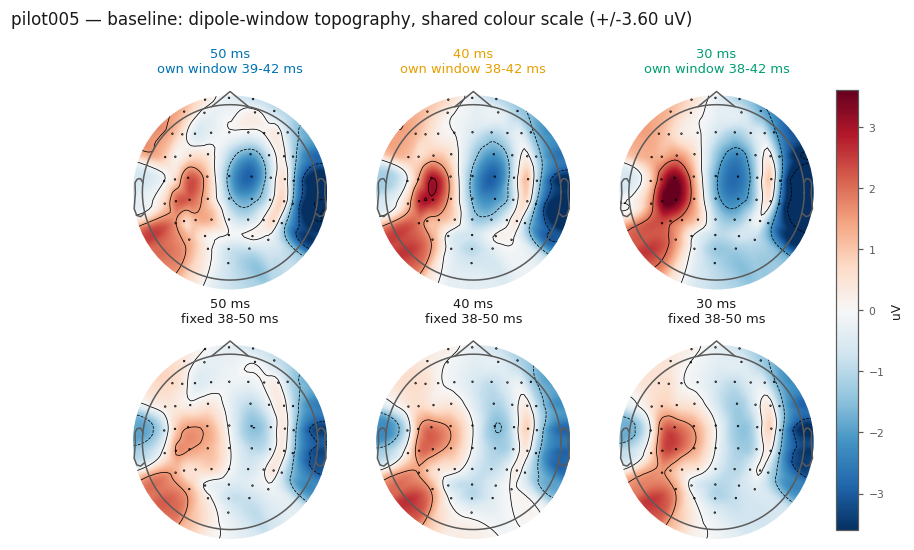

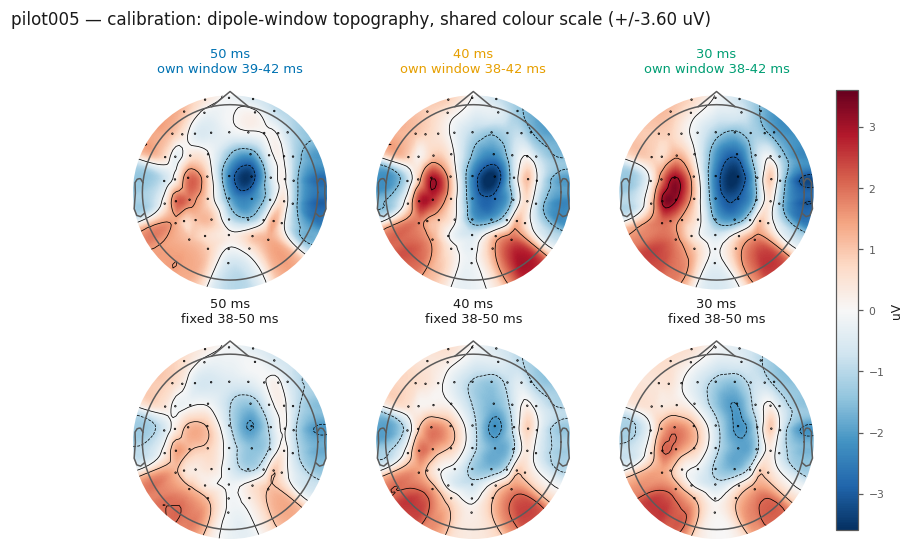

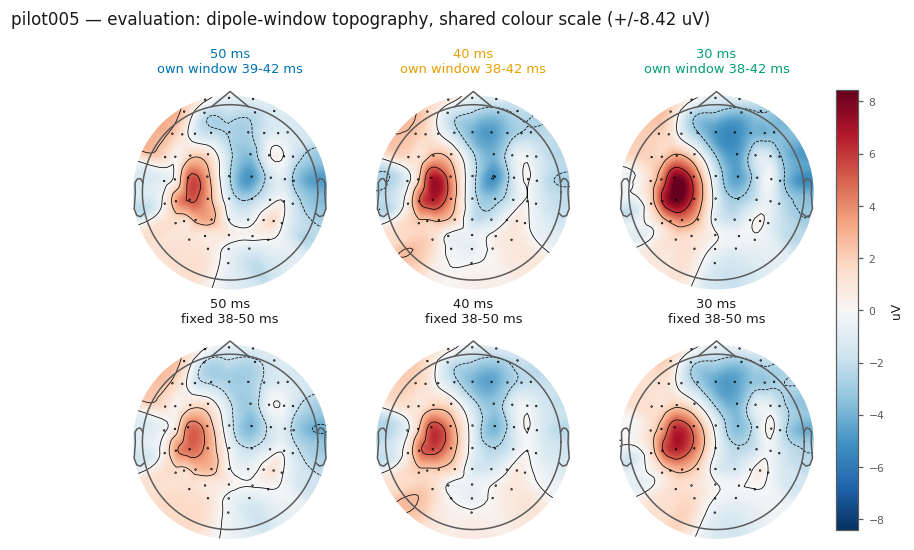

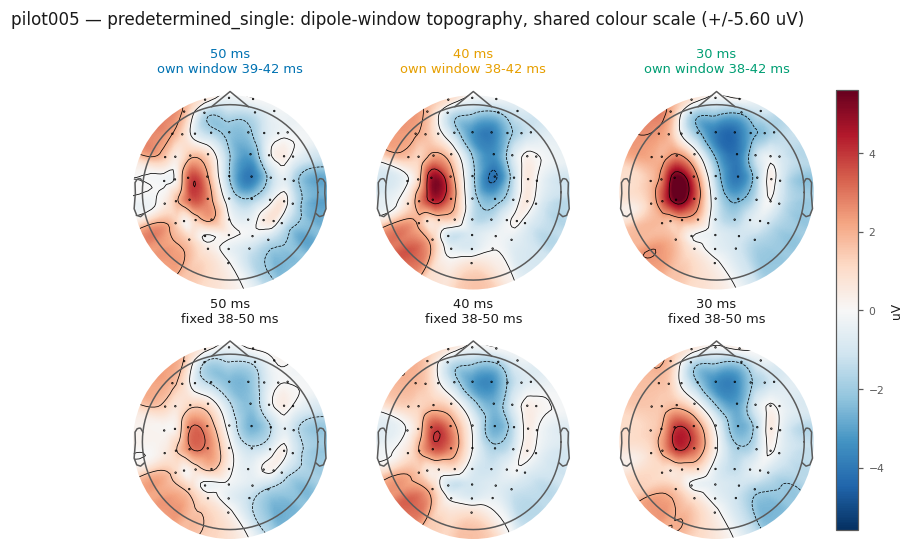

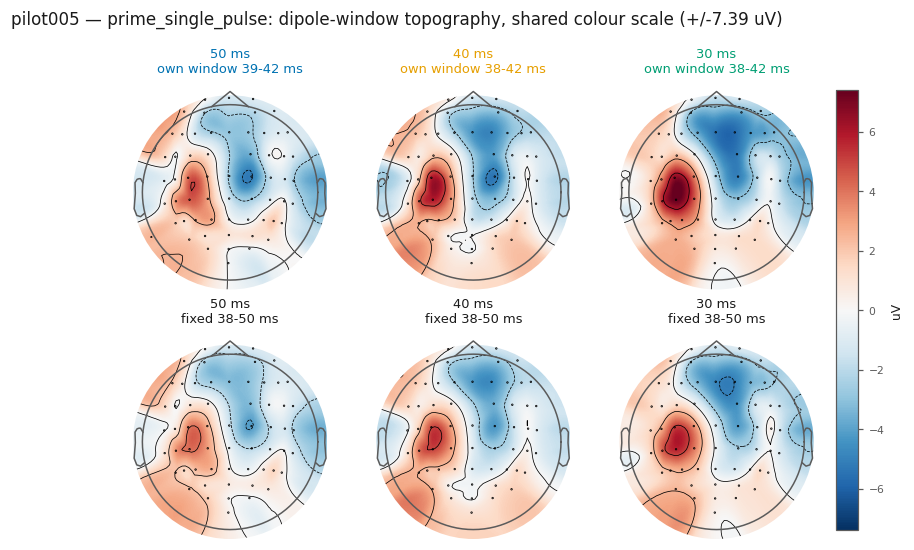

In [64]:
def fig_topo(subject, arm):
    info = CAL[subject][SETTINGS[0]]["pp"]._info_processed
    rows = []
    for T in SETTINGS:
        ev = arm_epochs(subject, arm, T, "final").mean(axis=0).astype(np.float64)
        ir = CAL[subject][T]["fitting_info"]["index_range"]
        own = slice(DIP_SL.start + ir[0], DIP_SL.start + ir[1])
        rows.append((T, ev[:, own].mean(axis=1), ev[:, DIP_SL].mean(axis=1),
                     POST_MS[own.start], POST_MS[own.stop - 1]))
    vmax = max(np.abs(np.concatenate([r[1], r[2]])).max() for r in rows)

    fig, axes = plt.subplots(2, len(SETTINGS), figsize=(2.5 * len(SETTINGS) + 1.1, 5.4))
    axes = np.atleast_2d(axes)
    for j, (T, own_map, fix_map, w0, w1) in enumerate(rows):
        for i, (data, lab) in enumerate([(own_map, f"own window {w0}-{w1} ms"),
                                         (fix_map, f"fixed {DIP_TMIN*1e3:.0f}-{DIP_TMAX*1e3:.0f} ms")]):
            im, _ = mne.viz.plot_topomap(data, info, axes=axes[i, j], show=False,
                                         cmap="RdBu_r", vlim=(-vmax, vmax), contours=4,
                                         sensors=True, outlines="head")
            axes[i, j].set_title(f"{T} ms\n{lab}", fontsize=8.5,
                                 color=T_COLOR[T] if i == 0 else INK)
    cb = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.03)
    cb.set_label("uV", fontsize=8)
    cb.ax.tick_params(labelsize=7)
    fig.suptitle(f"{subject} — {arm}: dipole-window topography, shared colour scale "
                 f"(+/-{vmax:.2f} uV)", x=0.005, ha="left", fontsize=11, y=1.0)
    return fig


for sub in SUBJECTS:
    for arm in SESS[sub]["arm_order"]:
        FIGS[(sub, f"topo_{arm}")] = fig_topo(sub, arm)
        plt.show()

---
## 7 · Global field power

GFP of the grand average, per arm. The shared stages are drawn once in grey; the three
settings' final epochs in colour. The log panel shows the whole epoch including the early
artifact; the linear panel is the TEP range the dipole is fitted in.

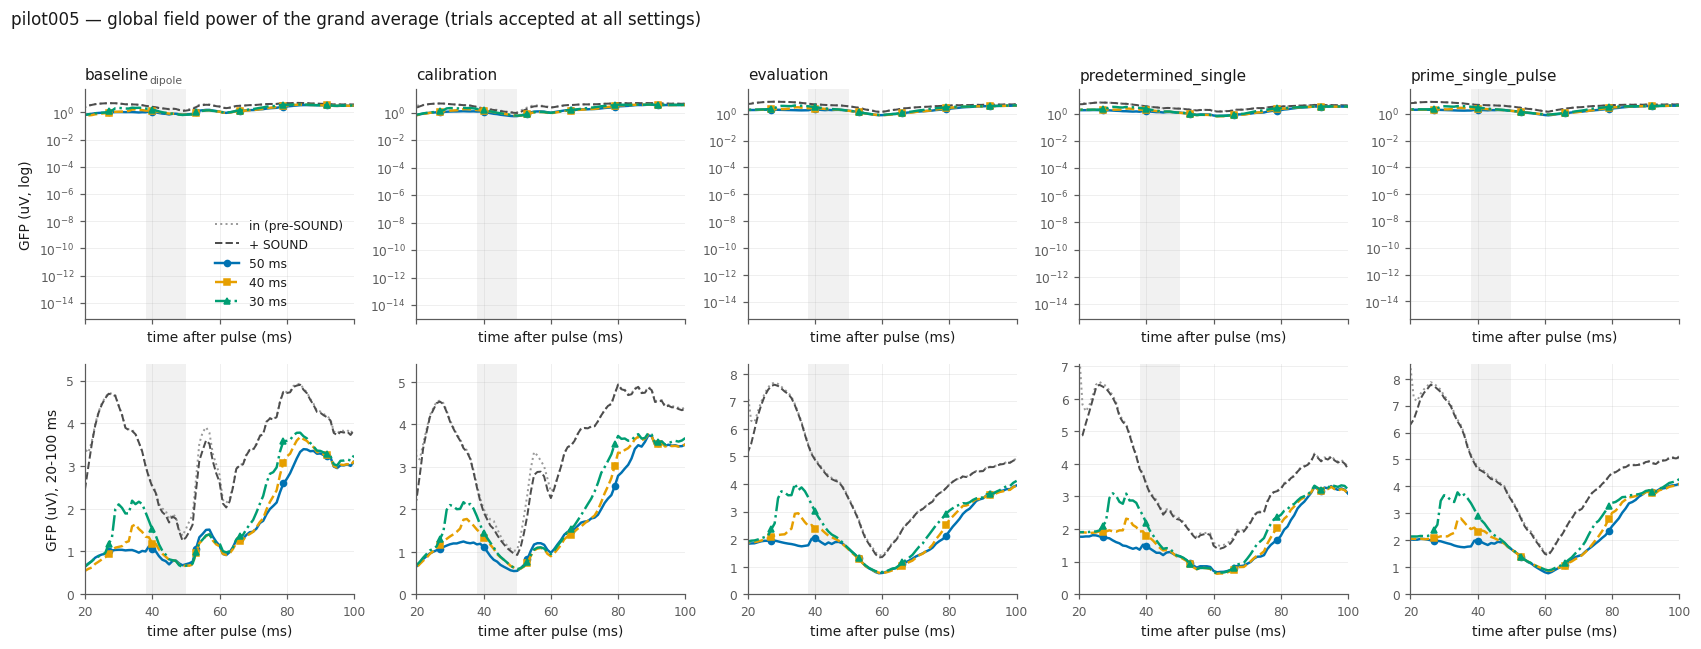

In [65]:
def fig_gfp(subject):
    arms = SESS[subject]["arm_order"]
    fig, axes = plt.subplots(2, len(arms), figsize=(3.1 * len(arms), 5.8), sharex="col")
    axes = np.atleast_2d(axes)
    for j, arm in enumerate(arms):
        pre = gfp(pre_sound_short(subject, arm).mean(axis=0))
        snd = gfp(arm_epochs(subject, arm, SETTINGS[0], "sound").mean(axis=0))
        fins = {T: gfp(arm_epochs(subject, arm, T, "final").mean(axis=0)) for T in SETTINGS}

        for i, logy in enumerate([True, False]):
            ax = axes[i, j]
            shade_dipole(ax, DIP_TMIN * 1e3, DIP_TMAX * 1e3, "dipole" if i == 0 and j == 0 else None)
            ax.plot(POST_MS, pre, **SHARED_STYLE["pre_sound"], lw=1.3)
            ax.plot(POST_MS, snd, **SHARED_STYLE["sound"], lw=1.3)
            for T in SETTINGS:
                ax.plot(POST_MS, fins[T], **t_style(T, markevery=13))
            if logy:
                ax.set_yscale("log")
                ax.set_title(arm, loc="left")
                ms_axis(ax)
            else:
                ax.set_xlim(20, 100)
                lo = min(f[(POST_MS >= 20)].min() for f in fins.values())
                hi = max(max(f[(POST_MS >= 20)].max() for f in fins.values()), snd[POST_MS >= 20].max())
                ax.set_ylim(0, hi * 1.1)
                ms_axis(ax)
            if j == 0:
                ax.set_ylabel("GFP (uV, log)" if logy else "GFP (uV), 20-100 ms")
            tidy(ax, legend=(i == 0 and j == 0))
    fig.suptitle(f"{subject} — global field power of the grand average "
                 f"(trials accepted at all settings)", x=0.005, ha="left", fontsize=11, y=1.01)
    fig.tight_layout()
    return fig


for sub in SUBJECTS:
    FIGS[(sub, "gfp")] = fig_gfp(sub)
    plt.show()

---
## 8 · TEP amplitudes

`DipoleFitter.fit_trial` in µA·m — the raw amplitude, not `tep_amplitude`, because the
normaliser is recalibrated per setting and its 0-1 output is not comparable across arms.

**Amplitudes are expected to rise as `T` falls**, for two reasons that are both "less
suppression": a lower blend weight in the dipole window, and one fewer principal component
removed. Read this figure with section 9, not on its own.

Each setting is measured in **its own** recalibrated dipole window and vertex (`amp`), and
again at the **reference** setting's vertex and window (`amp_refdip`), which separates "the
data changed" from "the dipole moved".

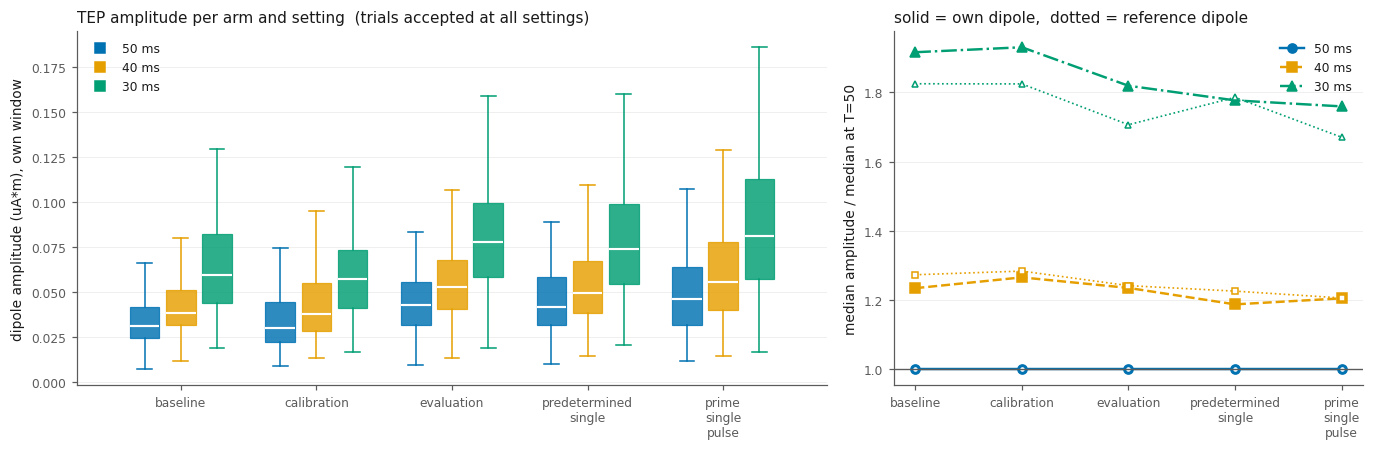

In [66]:
def fig_amp(subject):
    df = TRIALS[subject]
    d = df[df["stem"].isin(SESS[subject]["shared_accepted"])]
    arms = SESS[subject]["arm_order"]
    fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.2),
                             gridspec_kw=dict(width_ratios=[1.6, 1.0]))

    ax = axes[0]
    width = 0.8 / len(SETTINGS)
    for k, T in enumerate(SETTINGS):
        vals = [d[(d["arm"] == a) & (d["T"] == T)]["amp"].to_numpy() for a in arms]
        pos = np.arange(len(arms)) + (k - (len(SETTINGS) - 1) / 2) * width
        bp = ax.boxplot(vals, positions=pos, widths=width * 0.82, patch_artist=True,
                        showfliers=False, medianprops=dict(color="white", lw=1.4),
                        whiskerprops=dict(color=T_COLOR[T], lw=1.0),
                        capprops=dict(color=T_COLOR[T], lw=1.0))
        for b in bp["boxes"]:
            b.set(facecolor=T_COLOR[T], edgecolor=T_COLOR[T], alpha=0.82, lw=0.8)
        ax.plot([], [], marker="s", ls="none", color=T_COLOR[T], label=f"{T} ms")
    ax.set_xticks(np.arange(len(arms)), [a.replace("_", "\n") for a in arms], fontsize=8)
    ax.set_ylabel("dipole amplitude (uA*m), own window")
    ax.set_title("TEP amplitude per arm and setting  (trials accepted at all settings)", loc="left")
    ax.grid(axis="x", visible=False)
    tidy(ax)

    ax = axes[1]
    med = d.groupby(["arm", "T"])["amp"].median().unstack()
    medr = d.groupby(["arm", "T"])["amp_refdip"].median().unstack()
    x = np.arange(len(arms))
    for T in SETTINGS:
        ax.plot(x, (med.loc[arms, T] / med.loc[arms, REFERENCE_T]).to_numpy(),
                **t_style(T, markevery=1, markersize=6))
        ax.plot(x, (medr.loc[arms, T] / medr.loc[arms, REFERENCE_T]).to_numpy(),
                color=T_COLOR[T], ls=":", marker=T_MARKER[T], ms=4, mfc="white", lw=1.1)
    ax.axhline(1.0, color=MUTED, lw=0.9)
    ax.set_xticks(x, [a.replace("_", "\n") for a in arms], fontsize=8)
    ax.set_ylabel(f"median amplitude / median at T={REFERENCE_T}")
    ax.set_title("solid = own dipole,  dotted = reference dipole", loc="left")
    ax.grid(axis="x", visible=False)
    tidy(ax)
    fig.tight_layout()
    return fig


for sub in SUBJECTS:
    FIGS[(sub, "amp")] = fig_amp(sub)
    plt.show()

---
## 9 · Does a larger amplitude mean more signal?

Four companion measures, all on the trials accepted at every setting:

| measure | what a *better* setting does |
|---|---|
| evoked R² of the dipole fit | rises — the grand average is better explained by one dipole |
| median single-trial R² | rises |
| >100 Hz residual over 15-38 ms | falls — that is the muscle artifact SSP-SIR exists to remove |
| ρ(amplitude, RMS over 60-100 ms) | falls toward 0 — a high correlation means amplitude is tracking broadband noise outside the fitted window, not the N45 |

The muscle proxy is measured over **15-38 ms**, not the 1-15 ms window used elsewhere in
this project. `fix_stim_artifact(mode="window")` does not apply a `(1 - hanning)` taper as
the MNE docstring says: `_get_window` builds `[1, 0.25, 0, ..., 0, 0.25, 1]`, a hard blank
with two edge samples. Both calls cover 1-15 ms, and in the saved epochs samples **1-12 ms
are exactly 0.000**. A residual measured there is filter ringing, not muscle. 15-38 ms is
the first genuinely measured stretch, and it is where the residual actually sits
(per-sample RMS ≈ 56 µV over 16-30 ms against ≈ 3.5 µV over 31-50 ms).
`hf_early_blanked` is kept in the per-trial CSV for reference only.

The last one is the sharpest check: free-orientation `fit_trial` returns a non-negative
norm, so it has a noise floor, and on this session it correlates ρ ≈ +0.96 with amplitudes
fitted at *random* vertices. An amplitude rise accompanied by a rise here is a noise-floor
rise.

`k range 15-38 ms` from section 1 is repeated here: shortening `T` moves the kernel's step
earlier, into the 15-38 ms window, so this column says whether the artifact was removed or
merely relocated to a window that still feeds the gates and the topography.


=== pilot005 — amplitude with its companions ===
                               n  median amp (uA*m)  evoked R2  trial R2 (med)  >100Hz 15-38ms (uV)  rho(amp, late RMS)  k range 15-38  step in dip win
arm                  T (ms)                                                                                                                            
baseline             50       83            0.03106      0.617           0.518                 0.33               0.132         0.1348             True
                     40       83            0.03833      0.717           0.554                 0.42               0.183         0.3098            False
                     30       83            0.05950      0.818           0.659                 0.55               0.213         0.5650            False
calibration          50      110            0.02970      0.629           0.500                 0.32               0.348         0.1348             True
                     40      110      

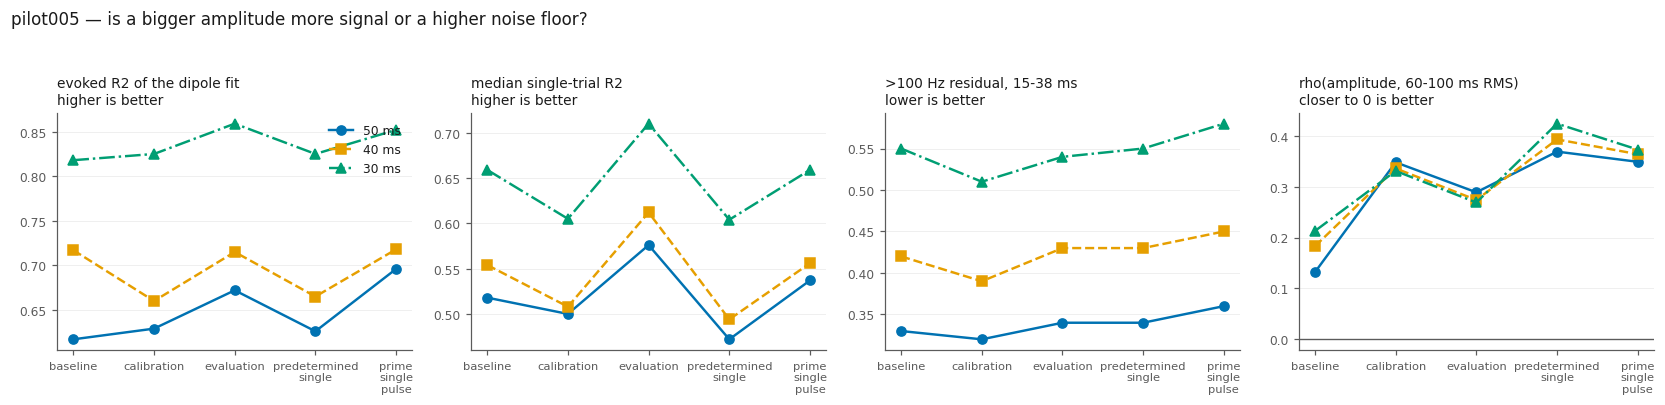

In [67]:
from scipy.stats import spearmanr


def diagnostics_table(subject):
    df = TRIALS[subject]
    d = df[df["stem"].isin(SESS[subject]["shared_accepted"])]
    ktab = KERNEL_TABLE[subject]
    rows = []
    for arm in SESS[subject]["arm_order"]:
        for T in SETTINGS:
            s = d[(d["arm"] == arm) & (d["T"] == T)]
            ev = arm_epochs(subject, arm, T, "final").mean(axis=0).astype(np.float64)
            evs = dipole_stats(CAL[subject][T]["fitter"], ev,
                               CAL[subject][T]["fitting_info"], DIP_SL)
            rho = spearmanr(s["amp"], s["norm_late"]).statistic if len(s) > 4 else np.nan
            rows.append({
                "arm": arm, "T (ms)": T, "n": len(s),
                "median amp (uA*m)": round(float(s["amp"].median()), 5),
                "evoked R2": round(float(evs["r2_free"]), 3),
                "trial R2 (med)": round(float(s["r2_free"].median()), 3),
                ">100Hz 15-38ms (uV)": round(float(s["hf_mid"].median()), 2),
                "rho(amp, late RMS)": round(float(rho), 3),
                "k range 15-38": ktab.loc[T, "k range 15-38"],
                "step in dip win": ktab.loc[T, "step in dipole win"],
            })
    return pd.DataFrame(rows).set_index(["arm", "T (ms)"])


DIAG = {}
for sub in SUBJECTS:
    DIAG[sub] = diagnostics_table(sub)
    print(f"\n=== {sub} — amplitude with its companions ===")
    print(DIAG[sub].to_string())


def fig_diag(subject):
    d = DIAG[subject].reset_index()
    arms = SESS[subject]["arm_order"]
    metrics = [("evoked R2", "evoked R2 of the dipole fit", "higher is better"),
               ("trial R2 (med)", "median single-trial R2", "higher is better"),
               (">100Hz 15-38ms (uV)", ">100 Hz residual, 15-38 ms", "lower is better"),
               ("rho(amp, late RMS)", "rho(amplitude, 60-100 ms RMS)", "closer to 0 is better")]
    fig, axes = plt.subplots(1, 4, figsize=(15.2, 3.5))
    x = np.arange(len(arms))
    for ax, (col, title, hint) in zip(axes, metrics):
        for T in SETTINGS:
            v = [d[(d["arm"] == a) & (d["T (ms)"] == T)][col].iloc[0] for a in arms]
            ax.plot(x, v, **t_style(T, markevery=1, markersize=6))
        ax.set_xticks(x, [a.replace("_", "\n") for a in arms], fontsize=7.5)
        ax.set_title(f"{title}\n{hint}", loc="left", fontsize=9)
        ax.grid(axis="x", visible=False)
        if col == "rho(amp, late RMS)":
            ax.axhline(0, color=MUTED, lw=0.9)
        tidy(ax, legend=(ax is axes[0]))
    fig.suptitle(f"{subject} — is a bigger amplitude more signal or a higher noise floor?",
                 x=0.005, ha="left", fontsize=11, y=1.04)
    fig.tight_layout()
    return fig


for sub in SUBJECTS:
    FIGS[(sub, "diag")] = fig_diag(sub)
    plt.show()

---
## 10 · Strongest and weakest quartiles

The split is **frozen at `QUARTILE_REF_T`** and applied unchanged to all three settings, so
the same trials are averaged everywhere and the difference between panels is processing
alone. Ranking per setting instead would let each setting pick its own trials, and the
comparison would mix processing with trial selection — the secondary panel and the overlap
count below show how much that matters.

Quartiles are taken within arm, on the trials accepted at every setting.

`[-30, +100] ms` is shown on the pre-SOUND stage, the one stage whose epoch genuinely
extends that far online. The SSP-SIR and final stages are shown over [1, 100] ms: the
kernel has one weight per sample of that window and none before it, and no kernel values
were invented to extend it.

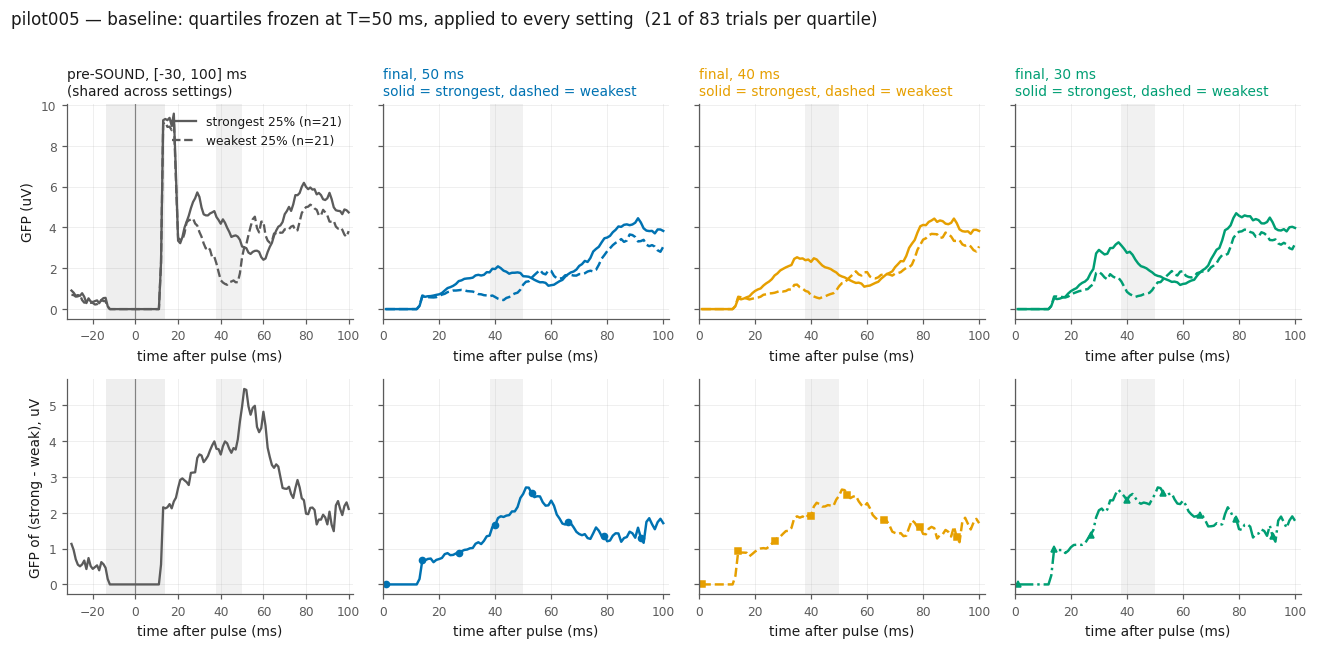

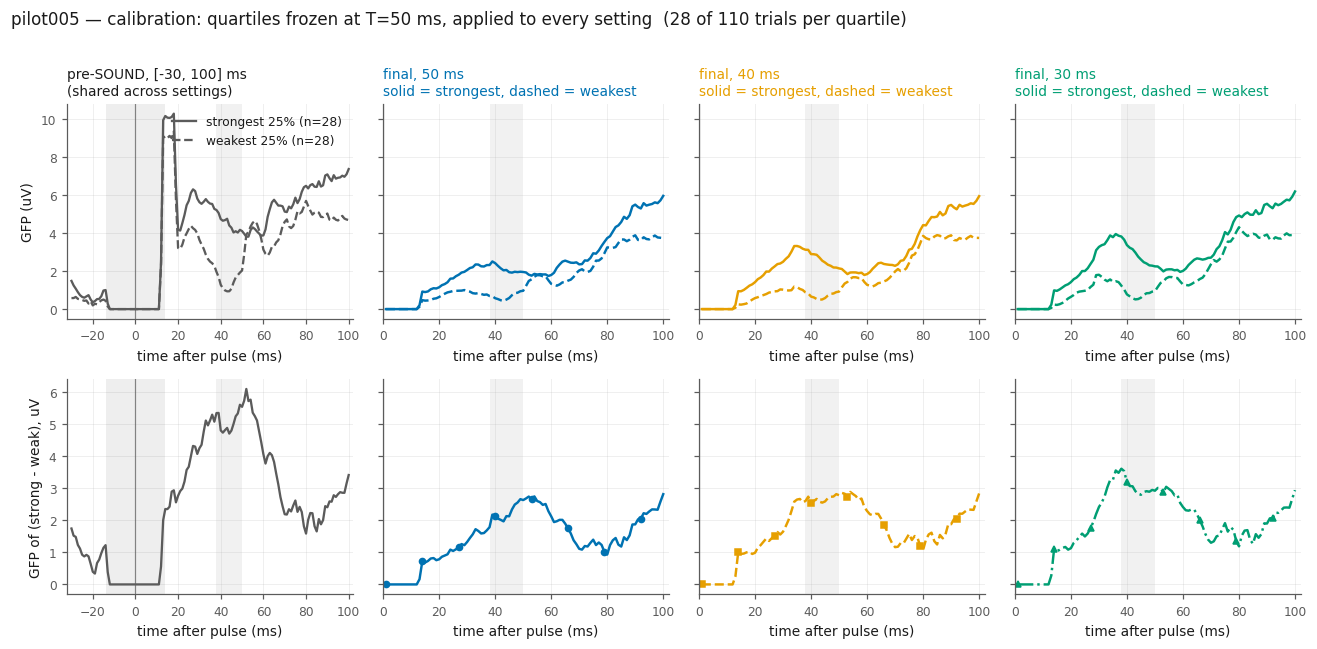

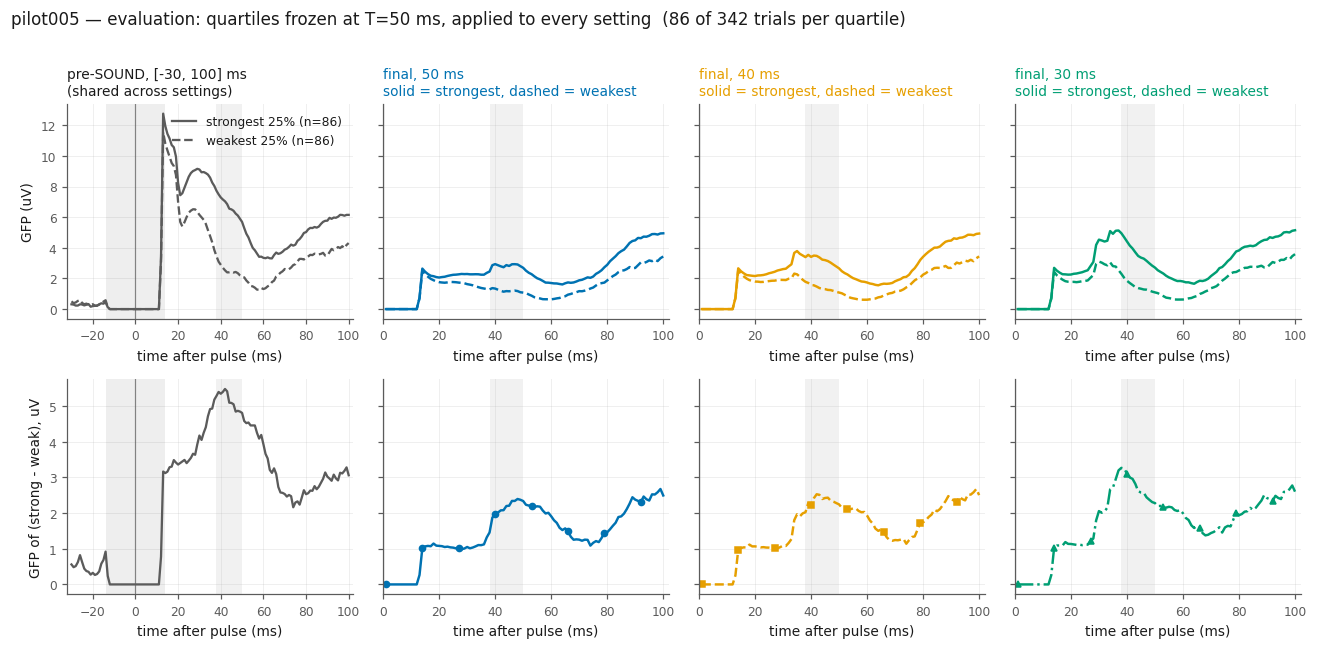

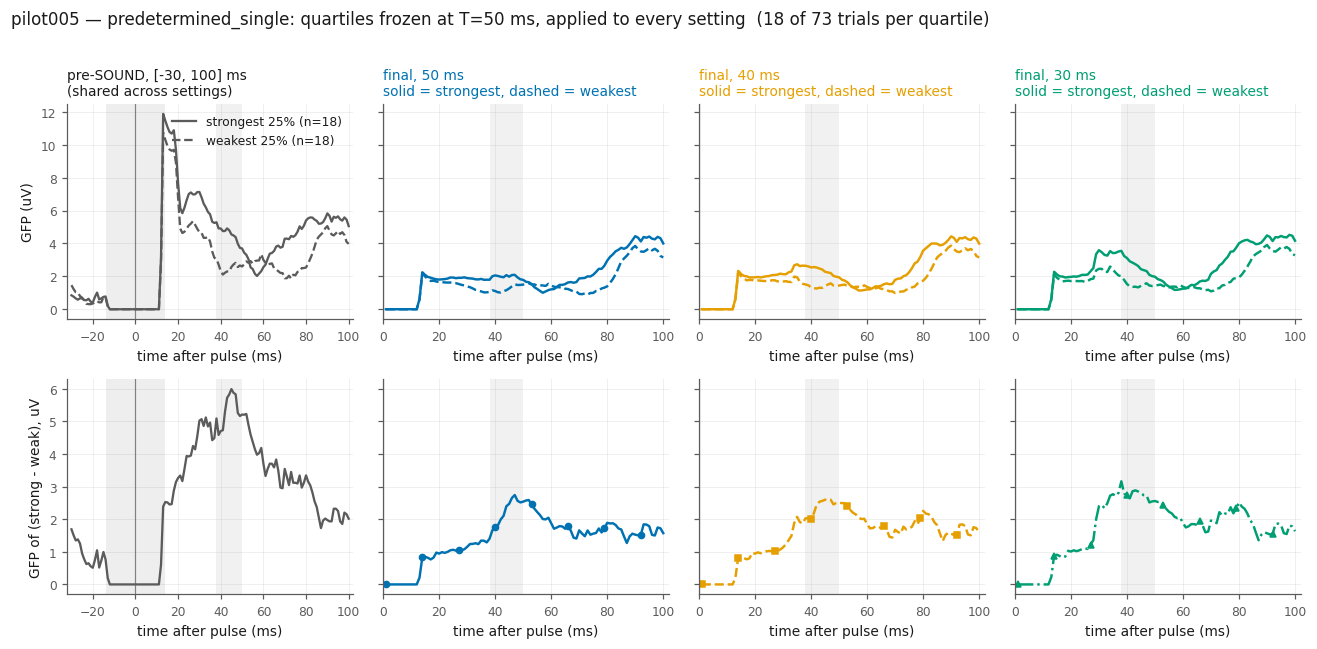

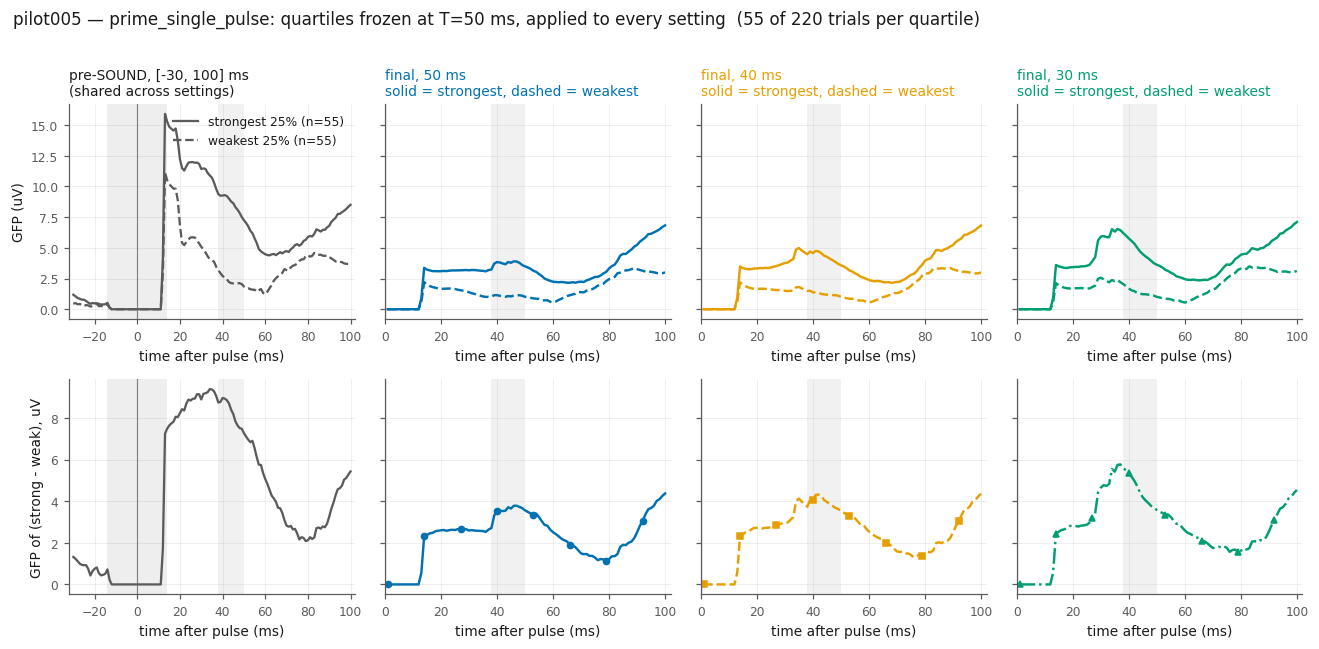

In [68]:
def quartile_sets(subject, arm, T, frac=0.25):
    df = TRIALS[subject]
    s = df[(df["arm"] == arm) & (df["T"] == T) &
           df["stem"].isin(SESS[subject]["shared_accepted"])]
    if len(s) < 8:
        return None
    k = max(1, int(round(len(s) * frac)))
    o = s.sort_values("amp")
    return dict(weak=set(o["stem"].head(k)), strong=set(o["stem"].tail(k)), k=k, n=len(s))


def fig_quartiles(subject, arm):
    ref = quartile_sets(subject, arm, QUARTILE_REF_T)
    if ref is None:
        return None
    lms = LONG_MS[subject]
    fig, axes = plt.subplots(2, len(SETTINGS) + 1, figsize=(3.0 * (len(SETTINGS) + 1), 5.8),
                             sharey="row")

    ax = axes[0, 0]
    for grp, ls in [("strong", "-"), ("weak", "--")]:
        ev = arm_epochs(subject, arm, SETTINGS[0], "pre_sound_long", stems=ref[grp]).mean(axis=0)
        ax.plot(lms, gfp(ev), color=MUTED, ls=ls, lw=1.5,
                label=f"{grp}est 25% (n={ref['k']})")
    ax.axvspan(-14, 14, color=INK, alpha=0.07, lw=0)
    shade_dipole(ax, DIP_TMIN * 1e3, DIP_TMAX * 1e3)
    ax.set_title("pre-SOUND, [-30, 100] ms\n(shared across settings)", loc="left", fontsize=9)
    ax.set_ylabel("GFP (uV)")
    ms_axis(ax, lms[0] - 2, lms[-1] + 2)
    tidy(ax)

    for j, T in enumerate(SETTINGS, start=1):
        ax = axes[0, j]
        shade_dipole(ax, DIP_TMIN * 1e3, DIP_TMAX * 1e3)
        for grp, ls in [("strong", "-"), ("weak", "--")]:
            ev = arm_epochs(subject, arm, T, "final", stems=ref[grp]).mean(axis=0)
            ax.plot(POST_MS, gfp(ev), color=T_COLOR[T], ls=ls, lw=1.6)
        ax.set_title(f"final, {T} ms\nsolid = strongest, dashed = weakest",
                     loc="left", fontsize=9, color=T_COLOR[T])
        ms_axis(ax, 0, 102)
        tidy(ax, legend=False)

    # bottom row: the difference strong - weak, which is what the split is meant to isolate
    ax = axes[1, 0]
    ev_s = arm_epochs(subject, arm, SETTINGS[0], "pre_sound_long", stems=ref["strong"]).mean(axis=0)
    ev_w = arm_epochs(subject, arm, SETTINGS[0], "pre_sound_long", stems=ref["weak"]).mean(axis=0)
    ax.plot(lms, gfp(ev_s - ev_w), color=MUTED, lw=1.5)
    ax.axvspan(-14, 14, color=INK, alpha=0.07, lw=0)
    shade_dipole(ax, DIP_TMIN * 1e3, DIP_TMAX * 1e3)
    ax.set_ylabel("GFP of (strong - weak), uV")
    ms_axis(ax, lms[0] - 2, lms[-1] + 2)
    tidy(ax, legend=False)
    for j, T in enumerate(SETTINGS, start=1):
        ax = axes[1, j]
        shade_dipole(ax, DIP_TMIN * 1e3, DIP_TMAX * 1e3)
        s = arm_epochs(subject, arm, T, "final", stems=ref["strong"]).mean(axis=0)
        w = arm_epochs(subject, arm, T, "final", stems=ref["weak"]).mean(axis=0)
        ax.plot(POST_MS, gfp(s - w), **t_style(T, markevery=13))
        ms_axis(ax, 0, 102)
        tidy(ax, legend=False)

    fig.suptitle(f"{subject} — {arm}: quartiles frozen at T={QUARTILE_REF_T} ms, applied to every "
                 f"setting  ({ref['k']} of {ref['n']} trials per quartile)",
                 x=0.005, ha="left", fontsize=11, y=1.01)
    fig.tight_layout()
    return fig


for sub in SUBJECTS:
    for arm in SESS[sub]["arm_order"]:
        f = fig_quartiles(sub, arm)
        if f is not None:
            FIGS[(sub, f"quartiles_{arm}")] = f
            plt.show()

In [69]:
# ---------------- how much the frozen split differs from ranking per setting
rows = []
for sub in SUBJECTS:
    ref = {a: quartile_sets(sub, a, QUARTILE_REF_T) for a in SESS[sub]["arm_order"]}
    for arm, r in ref.items():
        if r is None:
            continue
        for T in SETTINGS:
            own = quartile_sets(sub, arm, T)
            if own is None:
                continue
            rows.append({
                "subject": sub, "arm": arm, "T (ms)": T,
                "strong overlap": f"{len(r['strong'] & own['strong'])}/{r['k']}",
                "weak overlap": f"{len(r['weak'] & own['weak'])}/{r['k']}",
                "strong overlap %": round(100 * len(r["strong"] & own["strong"]) / r["k"]),
            })
OVERLAP = pd.DataFrame(rows, columns=["subject", "arm", "T (ms)", "strong overlap",
                                      "weak overlap", "strong overlap %"]
                       ).set_index(["subject", "arm", "T (ms)"])
print(f"Quartile membership: each setting's own ranking vs the frozen T={QUARTILE_REF_T} ms split")
print(OVERLAP.to_string())
print("\nA low overlap means ranking per setting would compare different trials, "
      "which is why the figures above use the frozen split.")

Quartile membership: each setting's own ranking vs the frozen T=50 ms split
                                     strong overlap weak overlap  strong overlap %
subject  arm                  T (ms)                                              
pilot005 baseline             50              21/21        21/21               100
                              40              19/21        16/21                90
                              30              17/21        16/21                81
         calibration          50              28/28        28/28               100
                              40              27/28        26/28                96
                              30              24/28        24/28                86
         evaluation           50              86/86        86/86               100
                              40              76/86        79/86                88
                              30              69/86        69/86                80
         pr

---
## 11 · Summary

One row per setting: what changed in the operator, what changed in the calibration, and
what changed in the outcome. The verdict column is deliberately not a ranking — it records
whether the kernel's step sits inside the window the dipole is fitted in, which is the one
thing this comparison establishes cleanly.

In [70]:
def summary(subject):
    kt, ct, dg = KERNEL_TABLE[subject], CAL_TABLE[subject], DIAG[subject].reset_index()
    pooled = dg[dg["arm"].isin(["evaluation", "predetermined_single", "prime_single_pulse"])]
    rows = []
    for T in SETTINGS:
        p = pooled[pooled["T (ms)"] == T]
        w = dg[dg["T (ms)"] == T]
        rows.append({
            "T (ms)": T,
            "step (ms)": kt.loc[T, "step (ms)"],
            "step inside dipole window": kt.loc[T, "step in dipole win"],
            "k swing in dipole window": kt.loc[T, "k range 38-50"],
            "k swing 15-38 ms": kt.loc[T, "k range 15-38"],
            "PCs removed": kt.loc[T, "n_pcs"],
            "cal trials kept": ct.loc[T, "kept"],
            "dipole window (ms)": ct.loc[T, "dipole win (ms)"],
            "d vertex vs ref (mm)": ct.loc[T, "d vertex (mm)"],
            "median amp, single pulses": round(float(p["median amp (uA*m)"].mean()), 5),
            "evoked R2 (mean over arms)": round(float(w["evoked R2"].mean()), 3),
            ">100Hz 15-38ms (mean, uV)": round(float(w[">100Hz 15-38ms (uV)"].mean()), 2),
            "rho(amp, late) mean": round(float(w["rho(amp, late RMS)"].mean()), 3),
        })
    return pd.DataFrame(rows).set_index("T (ms)")


SUMMARY = {}
for sub in SUBJECTS:
    SUMMARY[sub] = summary(sub)
    print(f"\n================ {sub} ================")
    print(SUMMARY[sub].to_string())
    print()
    kt = KERNEL_TABLE[sub]
    inside = [T for T in SETTINGS if kt.loc[T, "step in dipole win"]]
    outside = [T for T in SETTINGS if not kt.loc[T, "step in dipole win"]]
    print(f"kernel step inside the dipole window at: {inside or 'none'}")
    print(f"kernel step outside it at:               {outside or 'none'}")
    print(f"amplitude is expected to rise as T falls (lower k, fewer PCs removed); section 9 "
          f"says whether that rise is signal.")


================ pilot005 ================
       step (ms)  step inside dipole window  k swing in dipole window  k swing 15-38 ms  PCs removed  cal trials kept dipole window (ms)  d vertex vs ref (mm)  median amp, single pulses  evoked R2 (mean over arms)  >100Hz 15-38ms (mean, uV)  rho(amp, late) mean
T (ms)                                                                                                                                                                                                                                                               
50        38->39                       True                    0.2972            0.1348           15              107              39-42                   0.0                    0.04352                       0.648                       0.34                0.297
40        33->34                      False                    0.0903            0.3098           14              107              38-42                   7.5            

In [71]:
# ---------------------------------------------------------------- save
if SAVE_OUTPUTS:
    for sub in SUBJECTS:
        for T in SETTINGS:
            d = RESULTS_ROOT / f"sub-{sub}" / f"sspsir_{T}ms"
            d.mkdir(parents=True, exist_ok=True)
            c = CAL[sub][T]
            np.save(d / "calibration_bundle.npy", c["bundle"], allow_pickle=True)
            np.save(d / "dipole_fitting_info.npy", c["fitting_info"], allow_pickle=True)
            np.save(d / "calibration_amplitudes.npy", c["amps"])
            TRIALS[sub][TRIALS[sub]["T"] == T].to_csv(d / "trials.csv", index=False)
            (d / "calibration_log.txt").write_text(c["log"], encoding="utf-8")

        root = RESULTS_ROOT / f"sub-{sub}"
        TRIALS[sub].to_csv(root / "trials_all_settings.csv", index=False)
        KERNEL_TABLE[sub].to_csv(root / "kernel_operators.csv")
        CAL_TABLE[sub].to_csv(root / "calibration_comparison.csv")
        DIAG[sub].to_csv(root / "amplitude_diagnostics.csv")
        SUMMARY[sub].to_csv(root / "summary.csv")
        OVERLAP.loc[sub].to_csv(root / "quartile_overlap.csv")

        with PdfPages(root / f"sspsir_timerange_{sub}.pdf") as pdf:
            for (s, name), fig in FIGS.items():
                if s == sub:
                    pdf.savefig(fig, bbox_inches="tight")
        meta = dict(
            subject=sub, run_dir=str(SESS[sub]["dir"]), settings=SETTINGS,
            reference_T=REFERENCE_T, quartile_ref_T=QUARTILE_REF_T,
            limit_per_arm=LIMIT_PER_ARM, bootstrap_n=BOOTSTRAP_N,
            post_window_ms=[int(POST_MS[0]), int(POST_MS[-1])],
            dipole_window_ms=[DIP_TMIN * 1e3, DIP_TMAX * 1e3],
            n_trials=int(TRIALS[sub]["stem"].nunique()),
            n_accepted_all_settings=len(SESS[sub]["shared_accepted"]),
            mne=mne.__version__, numpy=np.__version__,
            written=time.strftime("%Y-%m-%d %H:%M:%S"),
        )
        (root / "run_info.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
        print(f"{sub}: wrote {root}")
else:
    print("SAVE_OUTPUTS is False — nothing written")

pilot005: wrote D:\Linus\Loop\offline_sspsir\sub-pilot005


In [72]:
# ---------------------------------------------------------------- closing check
check_prime_unchanged(PRIME_BEFORE, "at the end of the notebook")
after_pycache = {str(p) for p in PRIME_DIR.rglob("__pycache__")} - PYCACHE_BEFORE
print(f"__pycache__ dirs created in prime/ during this run: {len(after_pycache)}  (expected 0)")
print("\nprime/ was read only.")

prime/ unchanged at the end of the notebook: 50 .py files verified by SHA-256
__pycache__ dirs created in prime/ during this run: 0  (expected 0)

prime/ was read only.
